# Figures by source: CoralNet/Pacific re-evaluation

The data-size/quality, loss-weight, and cooldown-duration plots from `figures.ipynb`, redrawn from the
per-source re-evaluation (`eval_out/reeval_v2/aggregate.csv` and `per_source.csv`, written by
`scripts/compile_reeval.py`). Everything is the final checkpoint at 512 px, scored against the corrected
`configs/class_to_concepts.csv`. CoralNet val leaves out the sources in
`configs/eval/coralnet_val_excluded_sources.txt`.

Scopes of the taxonomic metrics:
- **all**: every point with a taxon at that rank, non-living (`none`) included
- **living**: not `none`, and for corals and echinoderms the `live` column is TRUE (dead coral is excluded)
- **live coral**: living scleractinians, octocorals, black corals, and hydrocorals (Millepora, Stylaster)

Every panel has two summary lines:
- **solid**: pooled over every point of every source (`aggregate.csv`)
- **dashed**: mean over sources, using only sources with at least `MIN_SUPPORT` scored points for that metric
  (living / live-coral points for those metrics, non-living points for non-living F1, true points for bleached/anthropogenic F1)

The by-source figures add one thin line per source. CoralNet sources are colored by their number of points
(log scale); the three Pacific sites are named in the legend.

Pacific panels also carry a dotted horizontal line: the final model (`cbm_final_res768`, step 10000) scored at
768 px on Pacific labeled corals, pooled over every point
(`eval_out/final_test/final_hires/cbm_final_res768/step10000_res768/summary.json`).

The dashed line is recomputed here from `per_source.csv` with the support filter, so it can differ from the
`*_macro_*` columns of `aggregate.csv`. Those average every source, including ones where a metric has no
support. For example, a source with no bleached points but a few false positives has bleached F1 = 0.

The re-evaluation does not include CoralscapesV2, so the 39-class probe panels from `figures.ipynb` are not
repeated here.

In [83]:
import json
import os
import re

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.labelsize": 10,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "lines.linewidth": 1.8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
})

EVAL = os.environ.get("MERMAIDSEG_EVAL_OUT", "/Users/jonathan/eval_out")
REEVAL = f"{EVAL}/reeval_v2"
PLOTS = "reefformer_plots/by_source"
os.makedirs(PLOTS, exist_ok=True)

RESOLUTION = 512
RANKS = ["kingdom", "phylum", "class", "order", "family", "genus"]
BINARY_CONCEPTS = ["bleached", "anthropogenic"]
EVALS = [("coralnet", "CoralNet val"), ("pacific", "Pacific labeled corals")]
# A source enters a per-source line or the dashed mean only with at least this
# many scored points for that metric.
MIN_SUPPORT = 20

agg = pd.read_csv(f"{REEVAL}/aggregate.csv")
per = pd.read_csv(f"{REEVAL}/per_source.csv", dtype={"unit": str})
agg = agg[(agg["done"].astype(str).str.lower() == "true") & (agg["resolution"] == RESOLUTION)].copy()
per = per[per["resolution"] == RESOLUTION].copy()
print(agg.groupby("experiment")["run"].count().rename("finished cells").to_string())
print(per.groupby("eval")["unit"].nunique().rename("sources").to_string())

experiment
baseline             1
data_quality         1
data_size            6
duration_cooldown    7
loss_weights         7
eval
coralnet    101
pacific       3


In [84]:
RANK_COLORS = dict(zip(RANKS, plt.cm.viridis(np.linspace(0.0, 0.9, len(RANKS)))))
DERIVED = {
    "tax_mean_acc_living": [f"tax_{r}_acc_living" for r in RANKS],
    "tax_mean_acc_all": [f"tax_{r}_acc_all" for r in RANKS],
    "tax_mean_macro_f1_living": [f"tax_{r}_macro_f1_living" for r in RANKS],
    "tax_mean_macro_f1_all": [f"tax_{r}_macro_f1_all" for r in RANKS],
    "tax_mean_acc_coral": [f"tax_{r}_acc_coral" for r in RANKS],
    "tax_mean_macro_f1_coral": [f"tax_{r}_macro_f1_coral" for r in RANKS],
    "binary_mean_f1": [f"{c}_f1" for c in BINARY_CONCEPTS],
}
# One panel row per metric in the scalar (data size, by-source) figures. Any
# per_source.csv metric column works here, e.g. "tax_family_macro_f1_living".
SCALAR_METRICS = [
    ("class_accuracy", "Class accuracy"),
    ("class_miou", "Class mIoU"),
    ("tax_genus_acc_living", "Genus accuracy (living)"),
    ("tax_mean_acc_living", "Mean rank accuracy (living)"),
    ("tax_genus_macro_f1_living", "Genus macro F1 (living)"),
    ("tax_mean_macro_f1_living", "Mean rank macro F1 (living)"),
    ("tax_mean_macro_f1_all", "Mean rank macro F1 (all)"),
    ("tax_genus_acc_coral", "Genus accuracy (live coral)"),
    ("tax_genus_macro_f1_coral", "Genus macro F1 (live coral)"),
    ("tax_mean_macro_f1_coral", "Mean rank macro F1 (live coral)"),
    ("tax_kingdom_f1_none", "Non-living F1"),
    ("bleached_f1", "Bleached F1"),
    ("anthropogenic_f1", "Anthropogenic F1"),
    ("hier_consistency_overall", "Hierarchical consistency"),
]
# Rows of the per-rank aggregate figures: (row label, [(metric, line label, color), ...]).
AGG_ROWS = [
    ("Class", [("class_accuracy", "Accuracy", "black"), ("class_miou", "mIoU", "tab:purple")]),
    *[
        (title, [(f"tax_{r}_{metric}", r, RANK_COLORS[r]) for r in RANKS])
        for metric, title in [
            ("acc_living", "Rank accuracy (living)"),
            ("macro_f1_living", "Rank macro F1 (living)"),
            ("macro_f1_all", "Rank macro F1 (all)"),
            ("acc_coral", "Rank accuracy (live coral)"),
            ("macro_f1_coral", "Rank macro F1 (live coral)"),
            ("f1_none", "Non-living F1"),
        ]
    ],
    ("Concept F1", [
        ("bleached_f1", "Bleached", "tab:blue"),
        ("anthropogenic_f1", "Anthropogenic", "tab:orange"),
    ]),
    ("Hierarchy", [
        ("hier_consistency_overall", "Consistency", "black"),
        ("hier_ece_mean", "Mean ECE", "tab:red"),
        ("hier_severity_mean_normalized", "Mistake severity (norm.)", "tab:brown"),
    ]),
]


def _support_column(key):
    """per_source.csv column with the point count behind ``key``."""
    if key.startswith("tax_"):
        rank, metric = key.removeprefix("tax_").split("_", 1)
        if metric in ("acc_living", "macro_f1_living"):
            return f"tax_{rank}_n_living"
        if metric in ("acc_coral", "macro_f1_coral"):
            return f"tax_{rank}_n_coral"
        if metric == "f1_none":
            return f"tax_{rank}_n_none"
        return f"tax_{rank}_n_all"
    for concept in BINARY_CONCEPTS:
        if key in (f"{concept}_f1", f"{concept}_precision", f"{concept}_recall"):
            return f"{concept}_n_true"
        if key == f"{concept}_accuracy":
            return f"{concept}_n_valid"
    return "num_points"


def values(frame, key, prefix="", min_support=None):
    """Metric ``key`` as floats. Derived keys are the mean of their parts (NaN if any is NaN).

    ``prefix`` is ``"coralnet_"``/``"pacific_"`` for aggregate.csv. With ``min_support``
    (per_source.csv only), entries backed by fewer points become NaN.
    """
    if key in DERIVED:
        parts = [values(frame, part, prefix, min_support) for part in DERIVED[key]]
        return pd.concat(parts, axis=1).mean(axis=1, skipna=False)
    column = f"{prefix}{key}"
    if column not in frame.columns:
        return pd.Series(np.nan, index=frame.index)
    out = pd.to_numeric(frame[column], errors="coerce")
    if min_support is not None:
        support_column = _support_column(key)
        if support_column not in frame.columns:
            raise KeyError(f"{support_column} not in per_source.csv; re-run scripts/compile_reeval.py")
        out = out.where(pd.to_numeric(frame[support_column], errors="coerce") >= min_support)
    return out


def label_of(key):
    return dict(SCALAR_METRICS).get(key, key.replace("_", " "))


def _source_colors(eval_key):
    """Consistent per-source colors: named sites for few sources, log(points) otherwise."""
    points = per[per["eval"] == eval_key].groupby("unit")["num_points"].max()
    if points.empty:
        return {}, None
    if len(points) <= 10:
        units = sorted(points.index)
        return dict(zip(units, plt.cm.tab10(np.arange(len(units))))), None
    norm = mpl.colors.LogNorm(vmin=max(points.min(), 1), vmax=max(points.max(), 2))
    cmap = plt.cm.viridis
    colors = {unit: cmap(norm(n)) for unit, n in points.items()}
    return colors, mpl.cm.ScalarMappable(norm=norm, cmap=cmap)


SOURCE_COLORS = {eval_key: _source_colors(eval_key) for eval_key, _ in EVALS}


def _line(axis, series, x, **kwargs):
    """Plot a run-indexed Series against ``x`` (run -> x), sorted by x."""
    data = pd.DataFrame({"x": series.index.map(x), "y": series.to_numpy()}).dropna().sort_values("x")
    if not data.empty:
        axis.plot(data["x"], data["y"], **kwargs)
    return data


def pooled(x, eval_key, key):
    sub = agg[agg["run"].isin(list(x))]
    return values(sub, key, prefix=f"{eval_key}_").groupby(sub["run"]).first()


def source_values(x, eval_key, key):
    sub = per[per["run"].isin(list(x)) & (per["eval"] == eval_key)]
    return sub.assign(_y=values(sub, key, min_support=MIN_SUPPORT))


def source_mean(x, eval_key, key):
    sub = source_values(x, eval_key, key)
    return sub.groupby("run")["_y"].mean()


def draw_summary(axis, x, eval_key, key, color="black", marker="x", label=None, mean=True):
    """Pooled line, and unless ``mean`` is false the dashed mean over sources."""
    _line(axis, pooled(x, eval_key, key), x, color=color, linestyle="-", marker=marker, zorder=4, label=label)
    if mean:
        _line(axis, source_mean(x, eval_key, key), x, color=color, linestyle="--", marker=marker, zorder=4)


def draw_sources(axis, x, eval_key, key):
    """One thin line per source; returns how many sources have a value."""
    colors, _ = SOURCE_COLORS[eval_key]
    sub = source_values(x, eval_key, key).dropna(subset=["_y"])
    few = len(colors) <= 10
    for unit, group in sub.groupby("unit"):
        _line(
            axis,
            group.set_index("run")["_y"],
            x,
            color=colors.get(unit, "gray"),
            linewidth=1.2 if few else 0.6,
            alpha=0.9 if few else 0.45,
            marker="." ,
            markersize=4 if few else 2,
            zorder=2,
            label=unit if few else None,
        )
    return sub["unit"].nunique()


STYLE_HANDLES = [
    Line2D([0], [0], color="black", linestyle="-", label="Pooled over all points"),
    Line2D([0], [0], color="black", linestyle="--", label=f"Mean over sources ($\\geq${MIN_SUPPORT} pts)"),
]


FINAL_SUMMARY = f"{EVAL}/final_test/final_hires/cbm_final_res768/step10000_res768/summary.json"
FINAL_LABEL = "Final model, Pacific (768 px)"
_TAX_SCALARS = (
    "acc_all", "acc_living", "acc_coral",
    "macro_f1_all", "macro_f1_living", "macro_f1_coral", "f1_none",
)


def _final_pacific(path):
    """Pooled Pacific scores of the final 768 px model, keyed like aggregate.csv."""
    with open(path) as handle:
        pooled = json.load(handle)["pacific"]["pooled"]
    row = {
        "class_accuracy": pooled.get("class_accuracy"),
        "class_miou": pooled.get("class_miou"),
    }
    for rank, block in (pooled.get("taxonomic") or {}).items():
        for key in _TAX_SCALARS:
            row[f"tax_{rank}_{key}"] = block.get(key)
    for concept in BINARY_CONCEPTS:
        block = pooled.get(concept) or {}
        for key in ("accuracy", "precision", "recall", "f1"):
            row[f"{concept}_{key}"] = block.get(key)
    for key, value in (pooled.get("hierarchical") or {}).items():
        if isinstance(value, (int, float)) and not isinstance(value, bool):
            row[re.sub(r"[^0-9a-zA-Z]+", "_", f"hier/{key}").strip("_")] = value
    frame = pd.DataFrame([row])
    for key in DERIVED:
        frame[key] = values(frame, key)
    scores = frame.iloc[0]
    print(
        f"final Pacific @ 768 px: class acc {scores['class_accuracy']:.3f}, "
        f"genus acc living {scores['tax_genus_acc_living']:.3f}, "
        f"mean rank acc living {scores['tax_mean_acc_living']:.3f}"
    )
    return scores


FINAL_PACIFIC = _final_pacific(FINAL_SUMMARY)
FINAL_HANDLE = Line2D([0], [0], color="black", linestyle=":", linewidth=1.2, label=FINAL_LABEL)


def draw_final(axis, eval_key, key, color="black"):
    """Dotted horizontal line at the final model's pooled Pacific score."""
    if eval_key != "pacific" or key not in FINAL_PACIFIC.index:
        return
    y = float(FINAL_PACIFIC[key])
    if np.isfinite(y):
        axis.axhline(y, color=color, linestyle=":", linewidth=1.2, zorder=4)


def _finish(fig, path, handles=STYLE_HANDLES, ncol=2):
    fig.legend(handles=handles, loc="outside upper center", ncol=ncol, fontsize=8, frameon=False)
    fig.savefig(path)
    plt.show()
    print(f"saved {path}")

final Pacific @ 768 px: class acc 0.563, genus acc living 0.713, mean rank acc living 0.806


## Experiment axes

Each experiment is a map from run to its x value.

Data size uses the training image counts from the earlier `eval_out/data_size/compiled.csv`. Those counts
come from the data-size profiles, not from the eval, so the earlier file is still valid. exp1 and exp2 start
at `exp1_drop0` (all CoralNet images), as in `figures.ipynb`. The full mix (`cbm_vitsize_vitl`) and the
sparsified full mix (`cbm_dq_sparse`) are separate markers at 447,411 images.

In [85]:
FULL_MIX_IMAGES = 447_411
COOLDOWN_ITERS = 25_000
CORALNET_ONLY = {"exp1", "exp2"}
DSIZE_EXPERIMENTS = [
    ("exp1", "CoralNet images, random", "tab:blue"),
    ("exp2", "CoralNet sources, most coral genera", "tab:orange"),
    ("exp3", "All images, random", "tab:green"),
    ("exp4", "Sources, most coral genera", "tab:red"),
]
BASELINE_RUN = "cbm_vitsize_vitl"
SPARSE_RUN = "cbm_dq_sparse"
BASELINE_LABEL = "Full training mix"
SPARSE_LABEL = "All dense data sparsified"
LOSS_WEIGHT_LABEL = "Per Image $\\longleftarrow$ Loss Weight $\\longrightarrow$ Per Pixel"


def _runs(experiment):
    return agg[agg["experiment"] == experiment]


x_loss = dict(zip(_runs("loss_weights")["run"], pd.to_numeric(_runs("loss_weights")["pix_weight"])))
x_duration = dict(
    zip(
        _runs("duration_cooldown")["run"],
        (pd.to_numeric(_runs("duration_cooldown")["cooldown_step"]) + COOLDOWN_ITERS) / 1000,
    )
)

size_path = f"{EVAL}/data_size/compiled.csv"
if os.path.isfile(size_path):
    _size = pd.read_csv(size_path)
    IMAGES = (
        _size.assign(n=pd.to_numeric(_size["n_images_kept"], errors="coerce"))
        .dropna(subset=["n"])
        .groupby("run")["n"]
        .first()
        .to_dict()
    )
else:
    print(f"{size_path} not found: data-size runs have no image counts")
    IMAGES = {}


def x_data_size(experiment):
    sub = _runs("data_size")
    sub = sub[
        (sub["dsize_experiment"] == experiment)
        & pd.to_numeric(sub["dsize_fraction"], errors="coerce").isin([0.1, 0.2, 0.5])
    ]
    runs = list(sub["run"])
    if experiment in CORALNET_ONLY and "cbm_dsize_exp1_drop0" in set(_runs("data_size")["run"]):
        runs.append("cbm_dsize_exp1_drop0")
    missing = [run for run in runs if run not in IMAGES]
    if missing:
        print(f"{experiment}: no training image count for {missing}; not plotted")
    return {run: IMAGES[run] for run in runs if run in IMAGES}


x_size = {experiment: x_data_size(experiment) for experiment, _, _ in DSIZE_EXPERIMENTS}
x_full_mix = {run: FULL_MIX_IMAGES for run in (BASELINE_RUN, SPARSE_RUN) if run in set(agg["run"])}
for name, x in [("loss weights", x_loss), ("duration", x_duration), *x_size.items(), ("full mix", x_full_mix)]:
    print(f"{name}: {len(x)} runs")

loss weights: 7 runs
duration: 7 runs
exp1: 4 runs
exp2: 3 runs
exp3: 0 runs
exp4: 0 runs
full mix: 2 runs


## Loss weights and duration: every rank, pooled vs. mean over sources

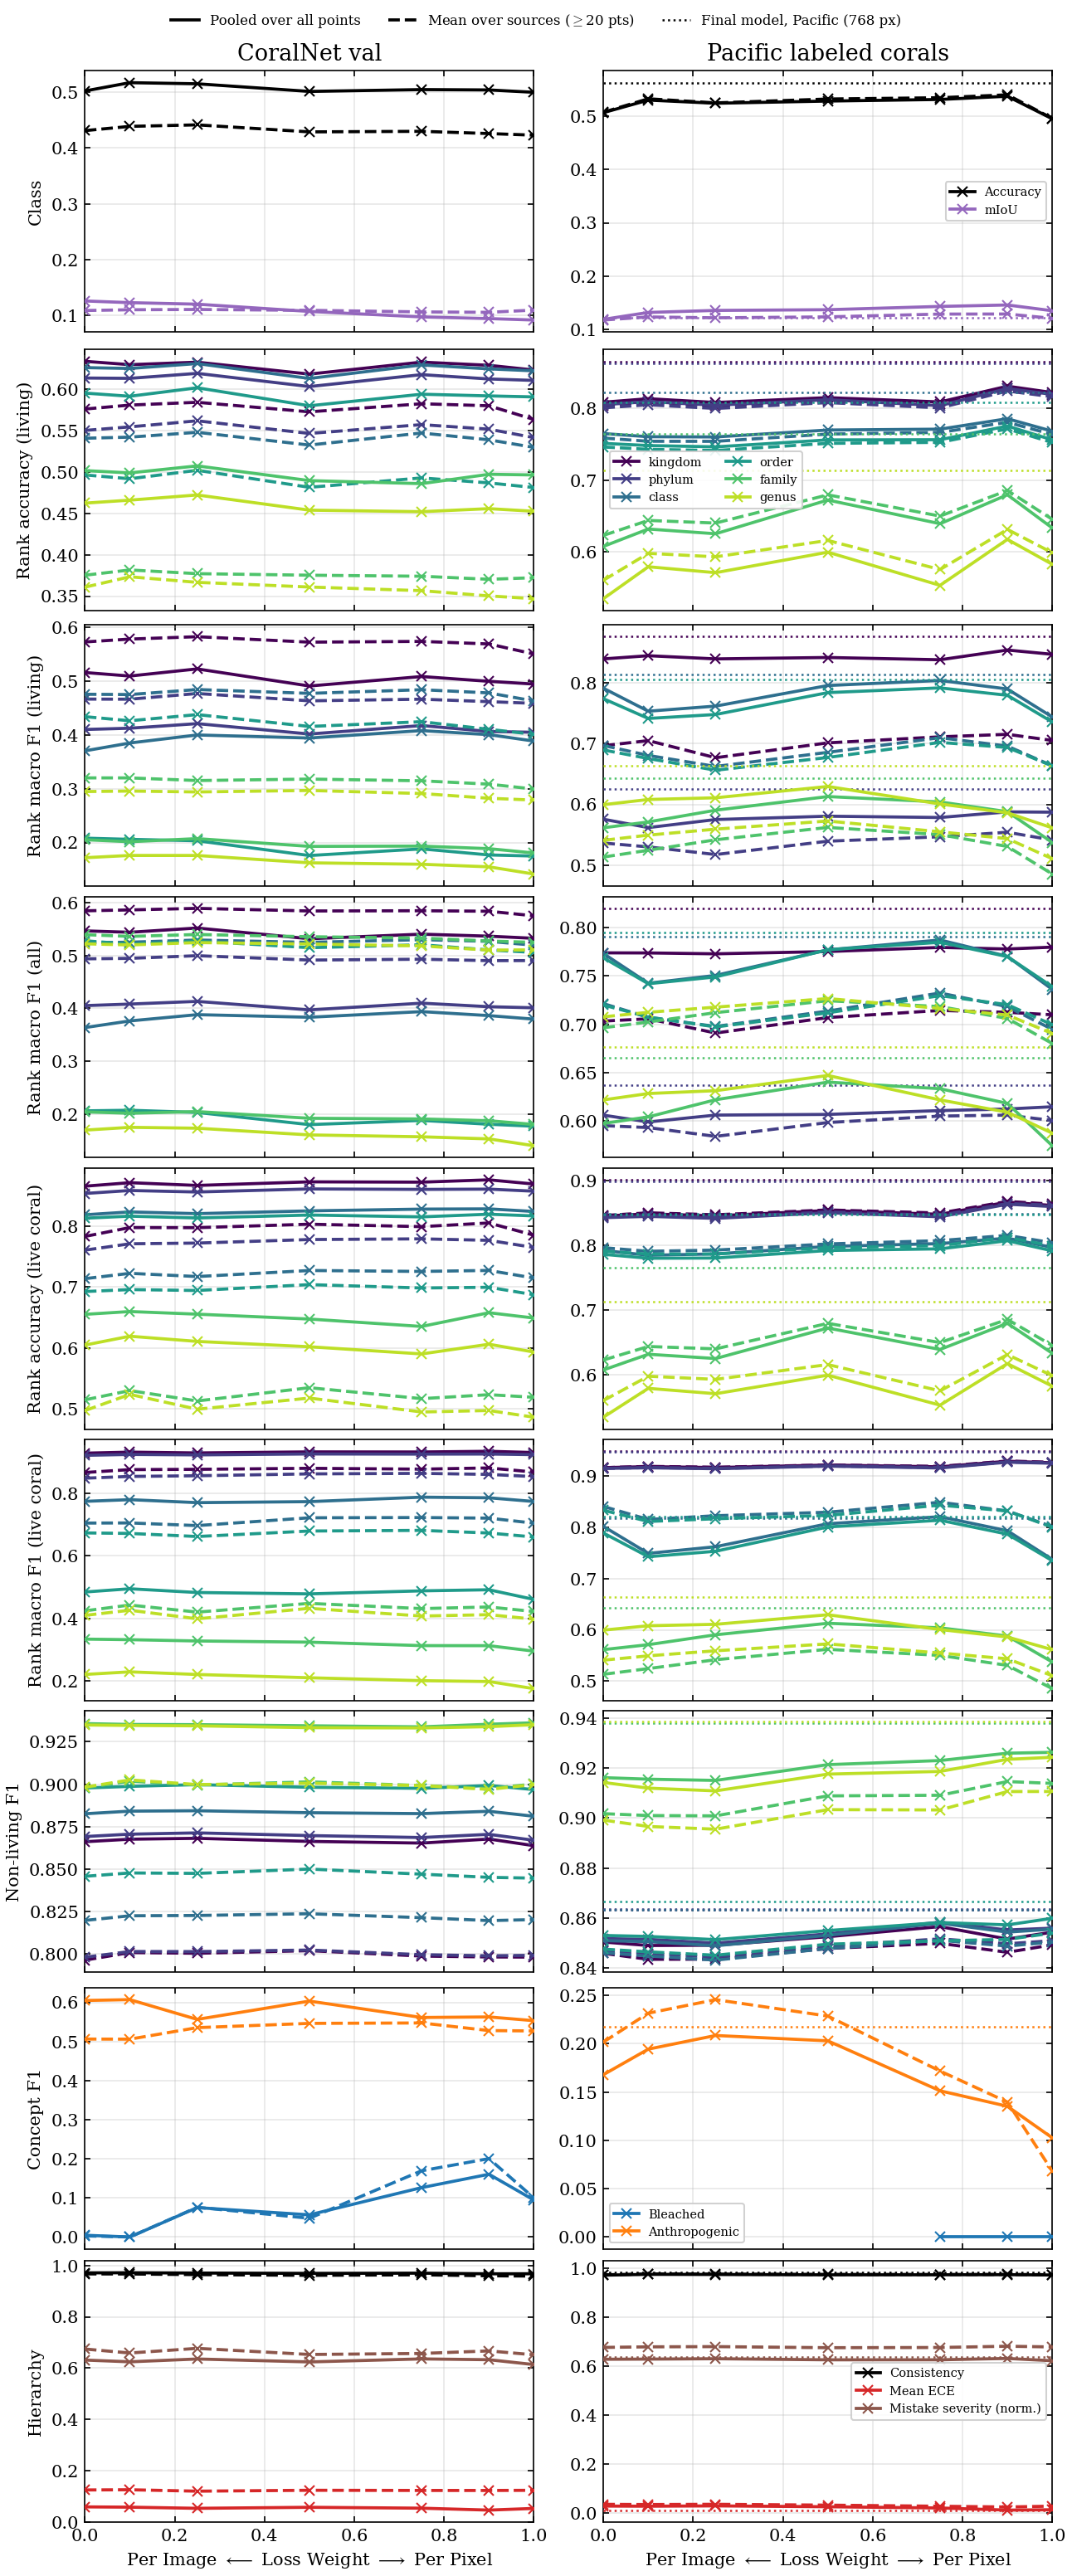

saved reefformer_plots/by_source/loss_weight_ranks.pdf


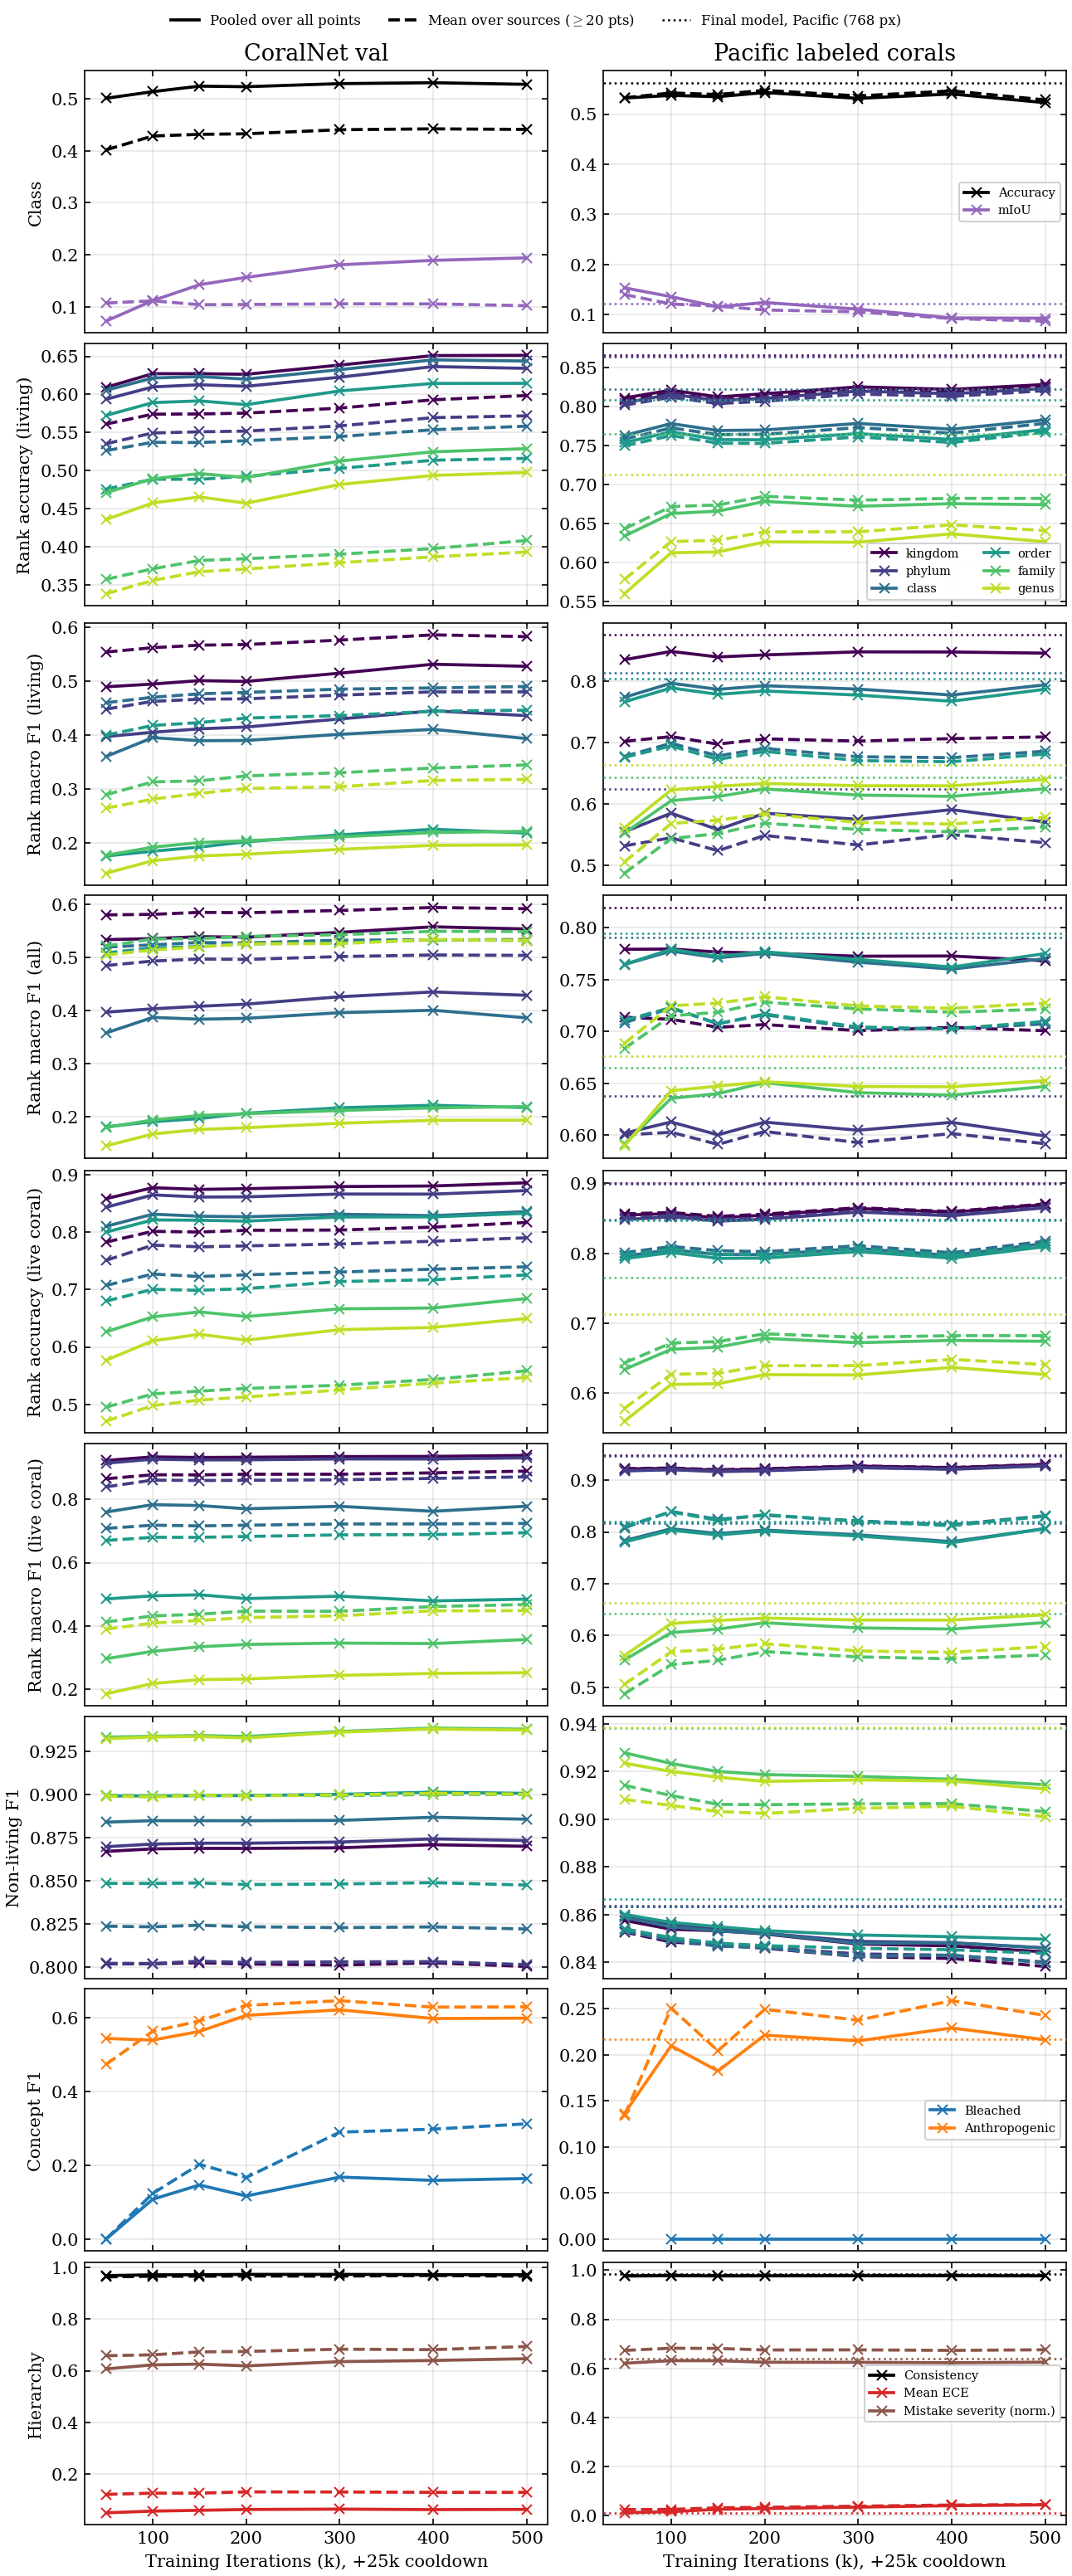

saved reefformer_plots/by_source/duration_ranks.pdf


In [86]:
def plot_aggregate(x, xlabel, path, xlim=None, xformatter=None):
    if not x:
        print(f"no finished cells for {path}")
        return
    fig, ax = plt.subplots(
        len(AGG_ROWS), len(EVALS), figsize=(8.6, 2.3 * len(AGG_ROWS)), sharex=True,
        squeeze=False, layout="constrained",
    )
    for col, (eval_key, eval_title) in enumerate(EVALS):
        ax[0, col].set_title(eval_title)
        for row, (row_title, lines) in enumerate(AGG_ROWS):
            axis = ax[row, col]
            for key, label, color in lines:
                draw_summary(axis, x, eval_key, key, color=color, label=label)
                draw_final(axis, eval_key, key, color=color)
            axis.grid(True, alpha=0.3)
            if col == 0:
                axis.set_ylabel(row_title)
            first_rank_row = row == next(i for i, (_, ls) in enumerate(AGG_ROWS) if ls[0][0].startswith("tax_"))
            if col == len(EVALS) - 1 and (not lines[0][0].startswith("tax_") or first_rank_row):
                axis.legend(fontsize=7, loc="best", framealpha=0.9, ncol=2 if len(lines) > 3 else 1)
            if xlim:
                axis.set_xlim(*xlim)
            if xformatter:
                axis.xaxis.set_major_formatter(xformatter)
    for axis in ax[-1]:
        axis.set_xlabel(xlabel)
    _finish(fig, path, handles=[*STYLE_HANDLES, FINAL_HANDLE], ncol=3)


plot_aggregate(x_loss, LOSS_WEIGHT_LABEL, f"{PLOTS}/loss_weight_ranks.pdf", xlim=(0, 1))
plot_aggregate(x_duration, "Training Iterations (k), +25k cooldown", f"{PLOTS}/duration_ranks.pdf")

## Loss weights and duration: one line per source

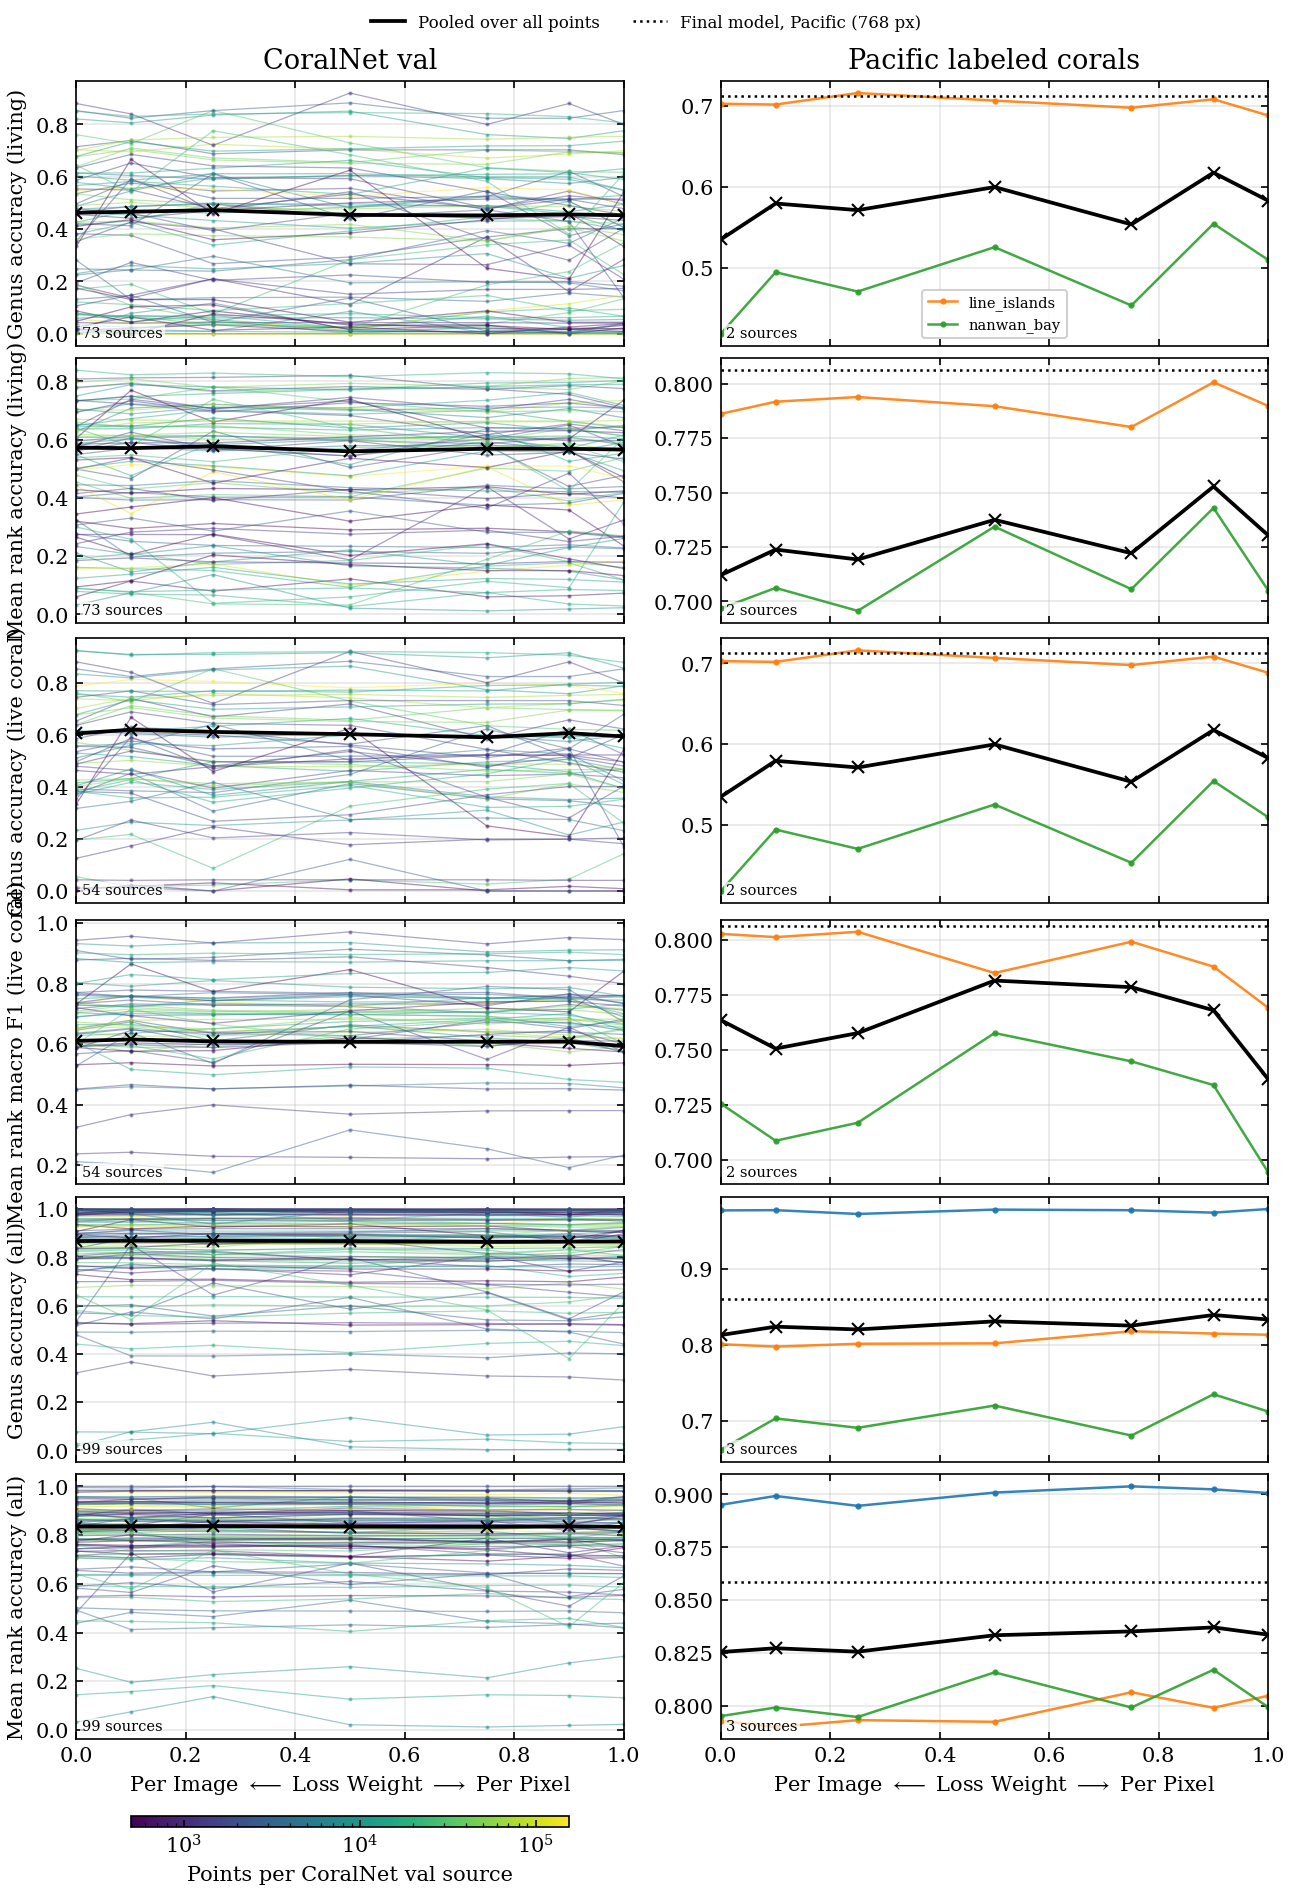

saved reefformer_plots/by_source/loss_weight_by_source.pdf


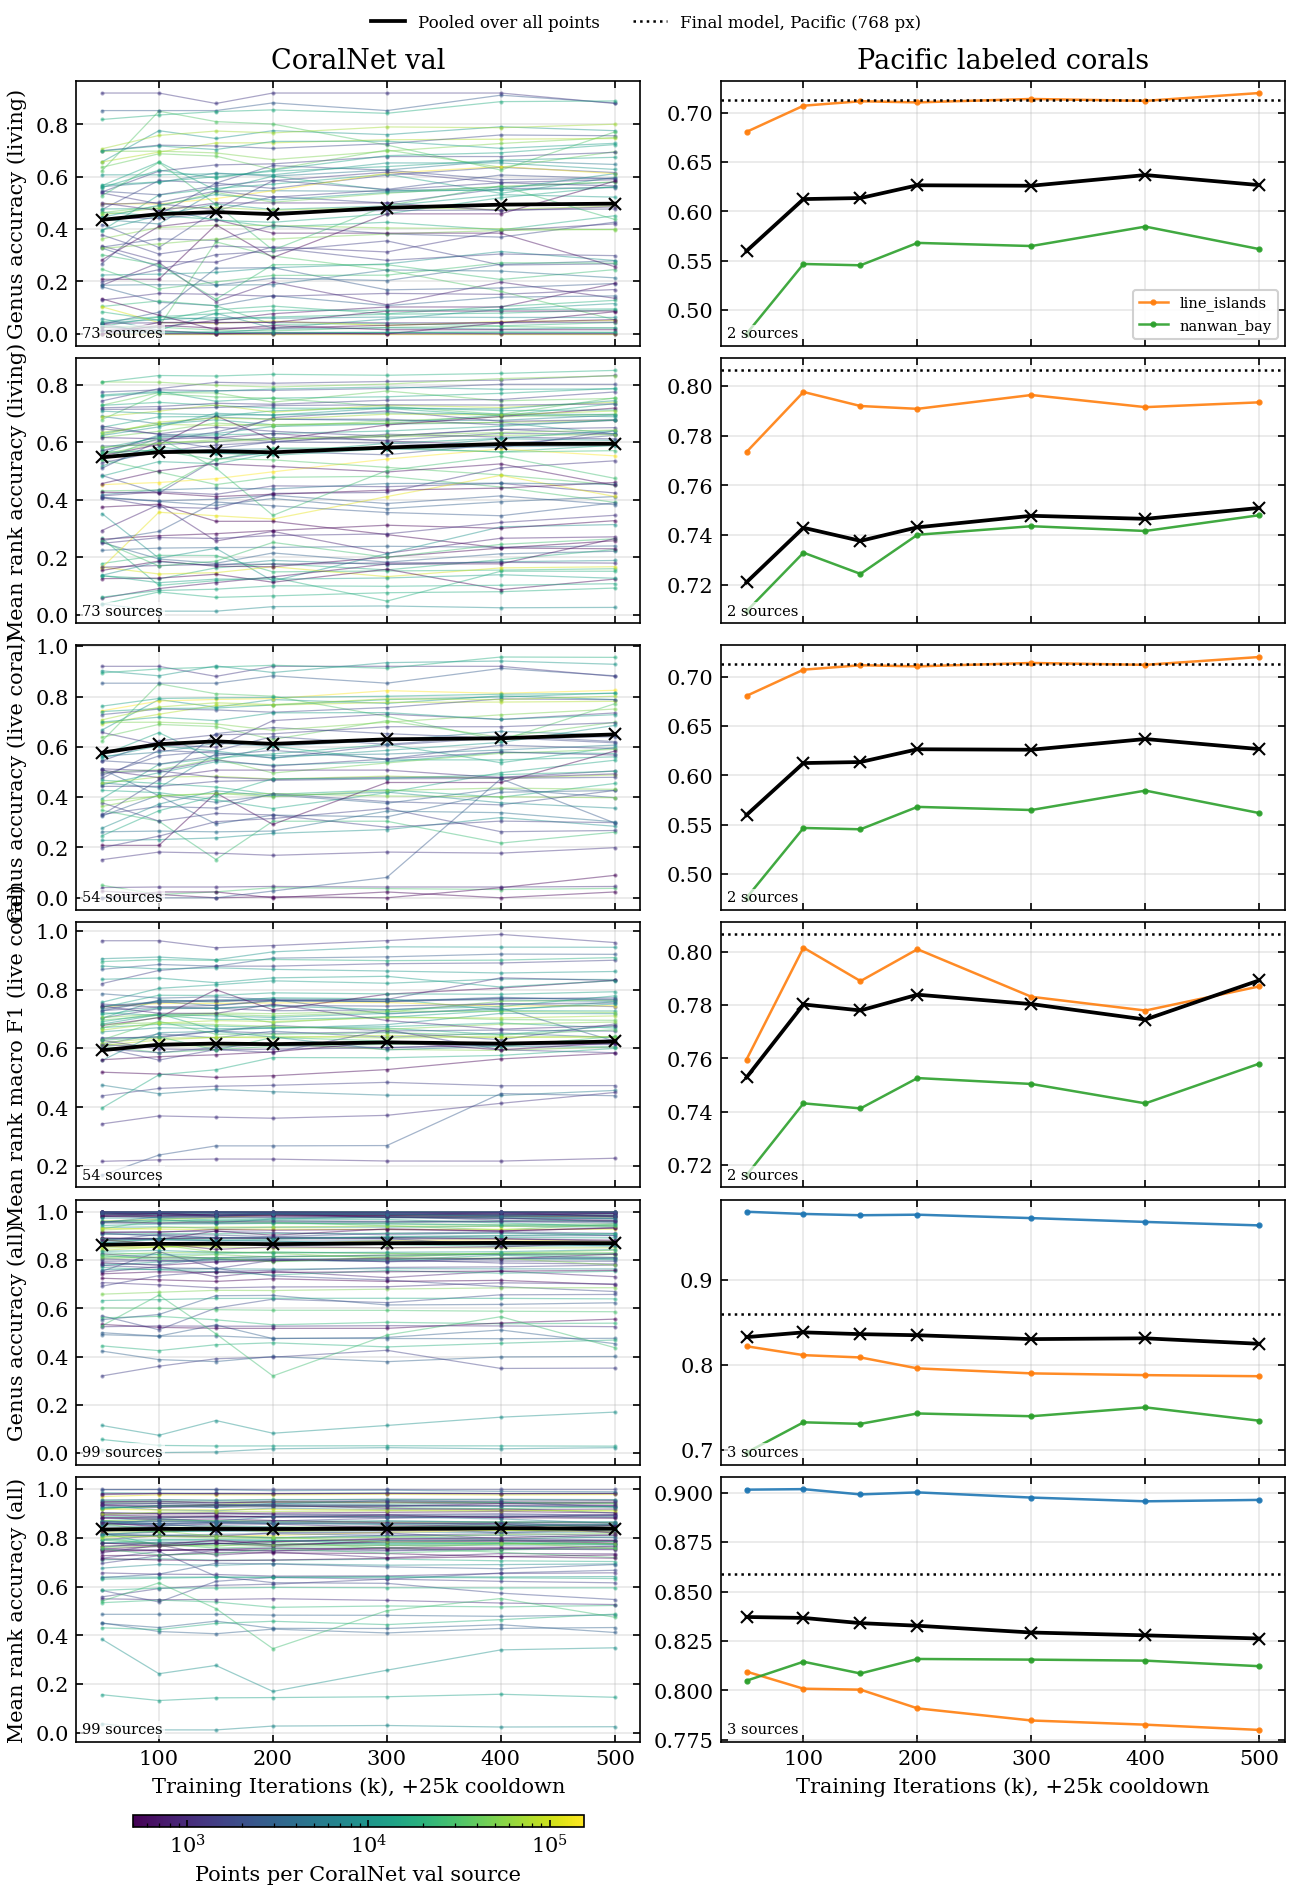

saved reefformer_plots/by_source/duration_by_source.pdf


In [87]:
BY_SOURCE_METRICS = [
    ("tax_genus_acc_living", "Genus accuracy (living)"),
    ("tax_mean_acc_living", "Mean rank accuracy (living)"),
    ("tax_genus_acc_coral", "Genus accuracy (live coral)"),
    ("tax_mean_macro_f1_coral", "Mean rank macro F1 (live coral)"),
    ("tax_genus_acc_all", "Genus accuracy (all)"),
    ("tax_mean_acc_all", "Mean rank accuracy (all)"),
]


def plot_by_source(x, xlabel, path, metrics=BY_SOURCE_METRICS, xlim=None, xformatter=None, extra=None):
    """Thin line per source, with the pooled line in black.

    ``extra(axis, eval_key, key)`` draws additional markers (data size).
    """
    if not x:
        print(f"no finished cells for {path}")
        return
    fig, ax = plt.subplots(
        len(metrics), len(EVALS), figsize=(8.6, 2.1 * len(metrics)), sharex=True,
        squeeze=False, layout="constrained",
    )
    for col, (eval_key, eval_title) in enumerate(EVALS):
        ax[0, col].set_title(eval_title)
        for row, (key, label) in enumerate(metrics):
            axis = ax[row, col]
            n_sources = draw_sources(axis, x, eval_key, key)
            draw_summary(axis, x, eval_key, key, mean=False)
            draw_final(axis, eval_key, key)
            if extra:
                extra(axis, eval_key, key)
            axis.text(0.01, 0.02, f"{n_sources} sources", transform=axis.transAxes, fontsize=7, va="bottom",
                      bbox={"facecolor": "white", "alpha": 0.7, "linewidth": 0, "pad": 1})
            axis.grid(True, alpha=0.3)
            if col == 0:
                axis.set_ylabel(label)
            if xlim:
                axis.set_xlim(*xlim)
            if xformatter:
                axis.xaxis.set_major_formatter(xformatter)
        colors, mappable = SOURCE_COLORS[eval_key]
        if mappable is not None:
            fig.colorbar(mappable, ax=ax[:, col], location="bottom", shrink=0.8, pad=0.01, aspect=40,
                         label=f"Points per {eval_title} source")
        elif colors:
            ax[0, col].legend(fontsize=7, loc="best", framealpha=0.9)
    for axis in ax[-1]:
        axis.set_xlabel(xlabel)
    _finish(fig, path, handles=[STYLE_HANDLES[0], FINAL_HANDLE], ncol=2)


plot_by_source(x_loss, LOSS_WEIGHT_LABEL, f"{PLOTS}/loss_weight_by_source.pdf", xlim=(0, 1))
plot_by_source(x_duration, "Training Iterations (k), +25k cooldown", f"{PLOTS}/duration_by_source.pdf")

## Loss weights and duration: one violin per x value

Each violin is the distribution of per-source scores at that training setting. Sources with fewer than `MIN_SUPPORT` scored points for the metric are left out. The black line is pooled over all points; the bar inside each violin is the median over sources.

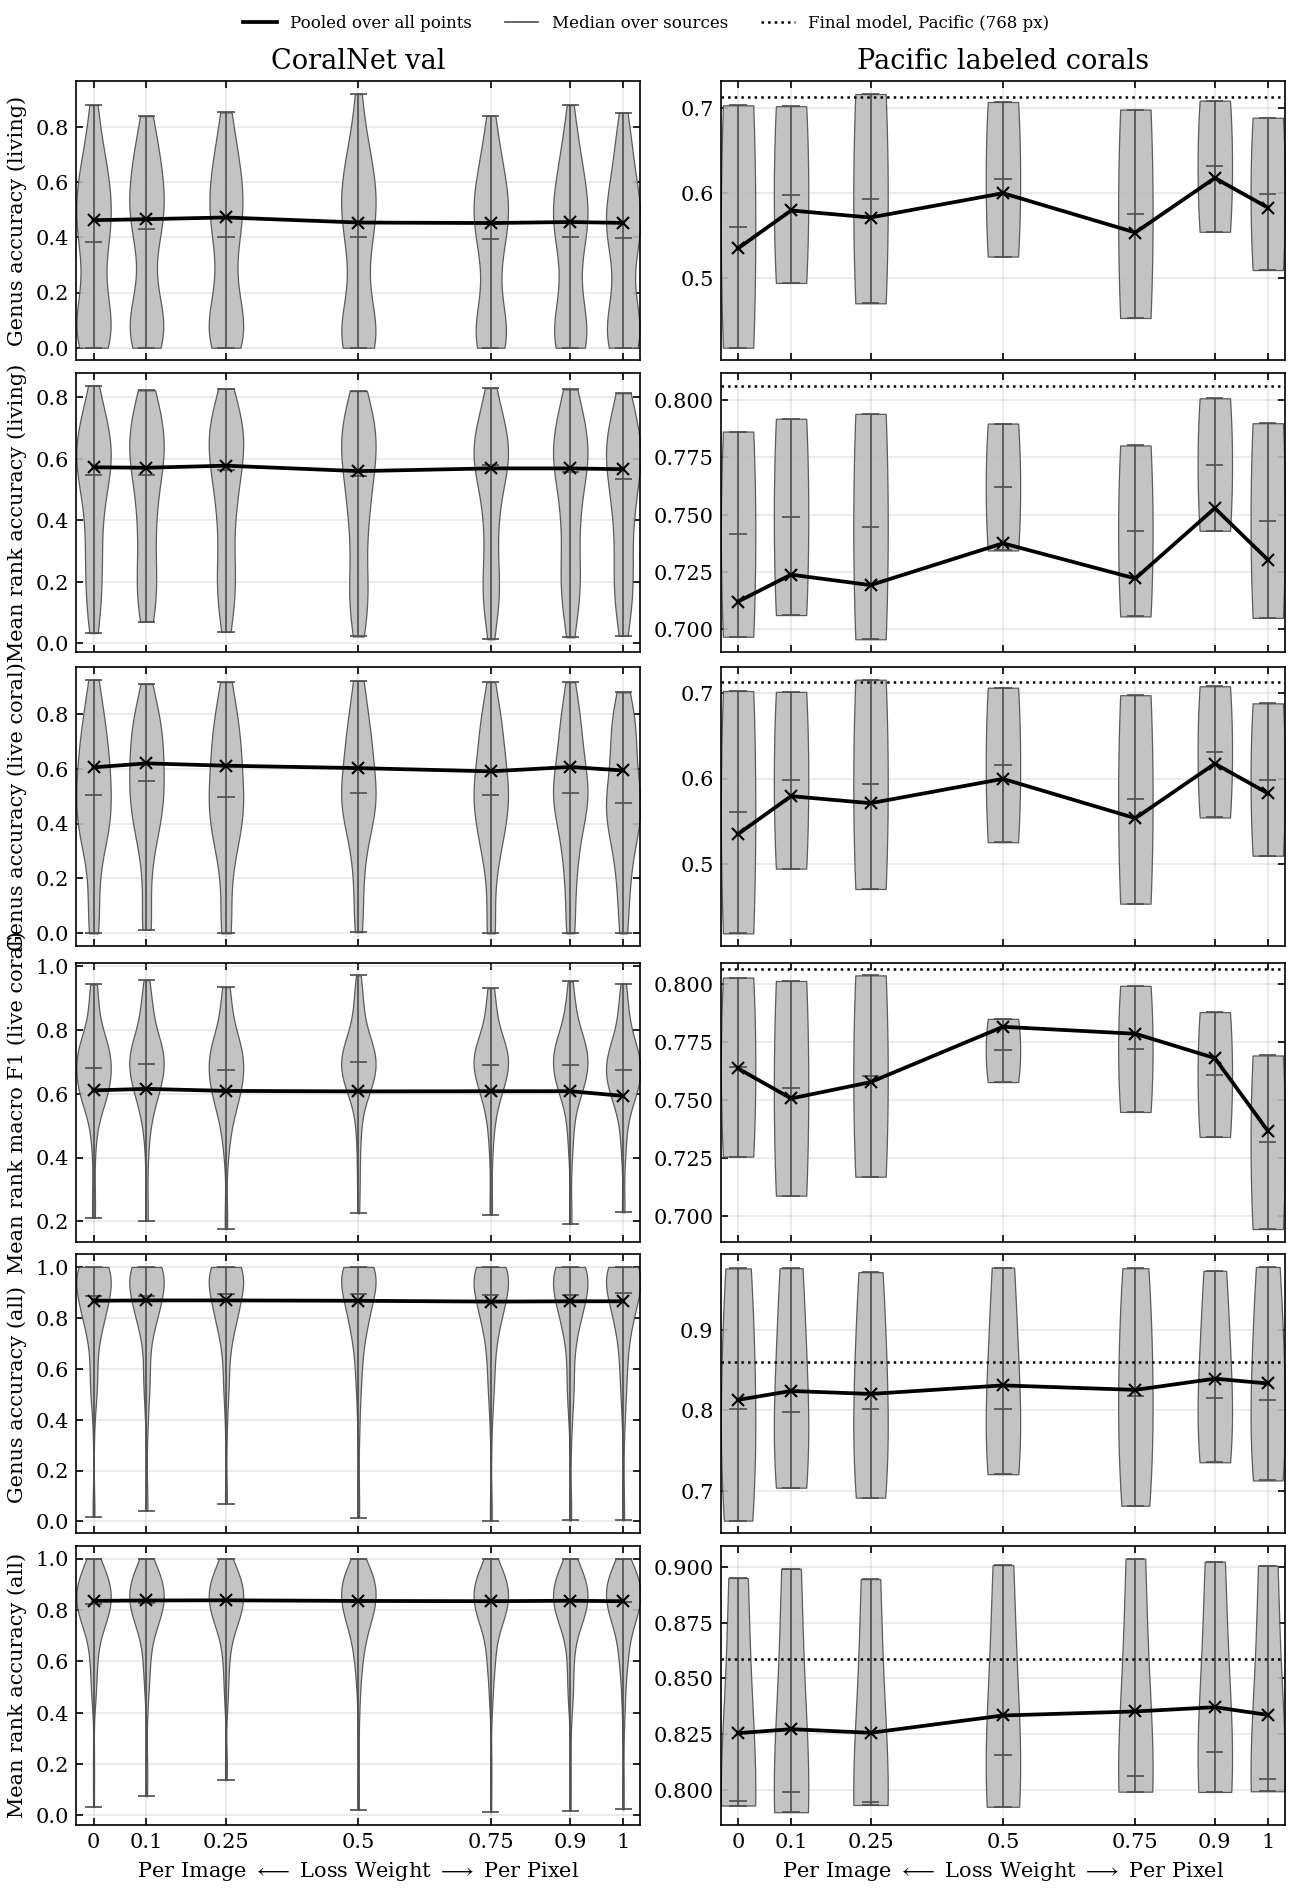

saved reefformer_plots/by_source/loss_weight_by_source_violin.pdf


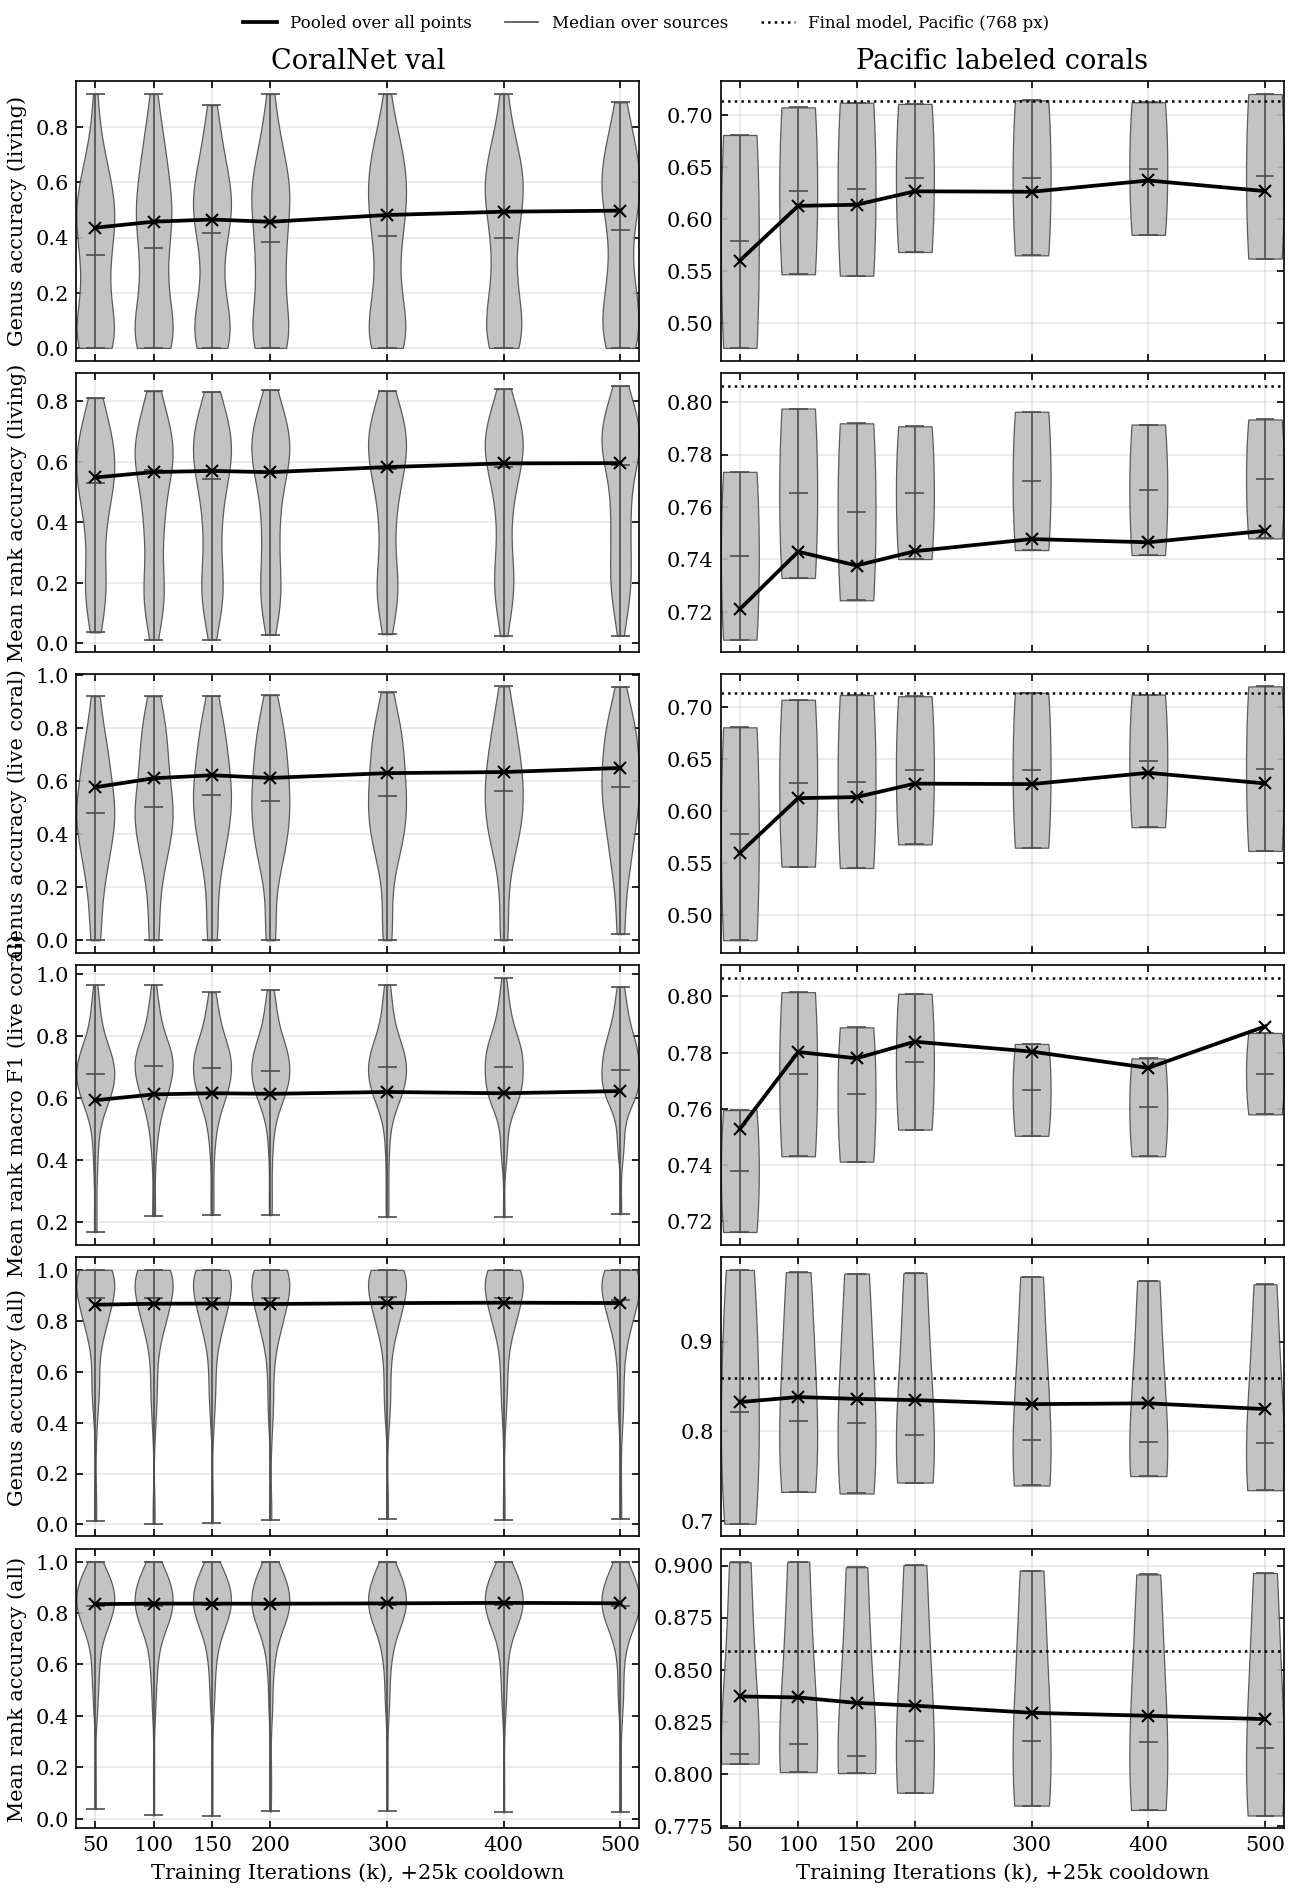

saved reefformer_plots/by_source/duration_by_source_violin.pdf


In [88]:
def _violin_width(positions):
    positions = np.unique(np.asarray(list(positions), dtype=float))
    if positions.size >= 2:
        return float(0.65 * np.diff(positions).min())
    span = abs(float(positions[0])) if positions.size else 1.0
    return 0.15 * span if span else 0.6


def plot_source_violins(x, xlabel, path, metrics=BY_SOURCE_METRICS, xlim=None, xformatter=None):
    """One violin of per-source scores at each x value, with the pooled line in black."""
    if not x:
        print(f"no finished cells for {path}")
        return
    ticks = np.unique(np.asarray(list(x.values()), dtype=float))
    width = _violin_width(ticks)
    fig, ax = plt.subplots(
        len(metrics), len(EVALS), figsize=(8.6, 2.1 * len(metrics)), sharex=True,
        squeeze=False, layout="constrained",
    )
    for col, (eval_key, eval_title) in enumerate(EVALS):
        ax[0, col].set_title(eval_title)
        for row, (key, label) in enumerate(metrics):
            axis = ax[row, col]
            sub = source_values(x, eval_key, key).dropna(subset=["_y"])
            sub = sub.assign(_x=sub["run"].map(x)).dropna(subset=["_x"])
            datasets, positions, flat = [], [], []
            for xpos, group in sub.groupby("_x", sort=True):
                ys = group["_y"].to_numpy()
                if ys.size >= 2 and np.ptp(ys) > 0:
                    datasets.append(ys)
                    positions.append(float(xpos))
                elif ys.size:
                    flat.append((float(xpos), float(np.median(ys))))
            if datasets:
                parts = axis.violinplot(
                    datasets,
                    positions=positions,
                    widths=width,
                    showmeans=False,
                    showmedians=True,
                    showextrema=True,
                )
                for body in parts["bodies"]:
                    body.set_facecolor("#bdbdbd")
                    body.set_edgecolor("#4d4d4d")
                    body.set_alpha(0.9)
                    body.set_linewidth(0.6)
                    body.set_zorder(2)
                for part_name in ("cbars", "cmins", "cmaxes", "cmedians"):
                    part = parts.get(part_name)
                    if part is not None:
                        part.set_color("#4d4d4d")
                        part.set_linewidth(0.8)
                        part.set_zorder(3)
            if flat:
                axis.hlines(
                    [y for _, y in flat],
                    [xpos - width / 2 for xpos, _ in flat],
                    [xpos + width / 2 for xpos, _ in flat],
                    color="#4d4d4d",
                    linewidth=0.8,
                    zorder=3,
                )
            draw_summary(axis, x, eval_key, key, mean=False)
            draw_final(axis, eval_key, key)
            axis.set_axisbelow(True)
            axis.grid(True, alpha=0.3)
            if col == 0:
                axis.set_ylabel(label)
            lo, hi = xlim if xlim else (float(ticks.min()), float(ticks.max()))
            axis.set_xlim(lo - width / 2, hi + width / 2)
            axis.set_xticks(ticks)
            axis.xaxis.set_major_formatter(
                xformatter or mpl.ticker.FuncFormatter(lambda value, _pos: f"{value:g}")
            )
    for axis in ax[-1]:
        axis.set_xlabel(xlabel)
    _finish(
        fig,
        path,
        handles=[
            STYLE_HANDLES[0],
            Line2D([0], [0], color="#4d4d4d", linewidth=0.8, label="Median over sources"),
            FINAL_HANDLE,
        ],
        ncol=3,
    )


plot_source_violins(
    x_loss, LOSS_WEIGHT_LABEL, f"{PLOTS}/loss_weight_by_source_violin.pdf", xlim=(0, 1),
)
plot_source_violins(
    x_duration, "Training Iterations (k), +25k cooldown", f"{PLOTS}/duration_by_source_violin.pdf",
)

## Data size and quality: pooled vs. mean over sources

The same layout as the data-size figure in `figures.ipynb`, with the new metrics. Filled markers are pooled
and hollow markers are the mean over sources.

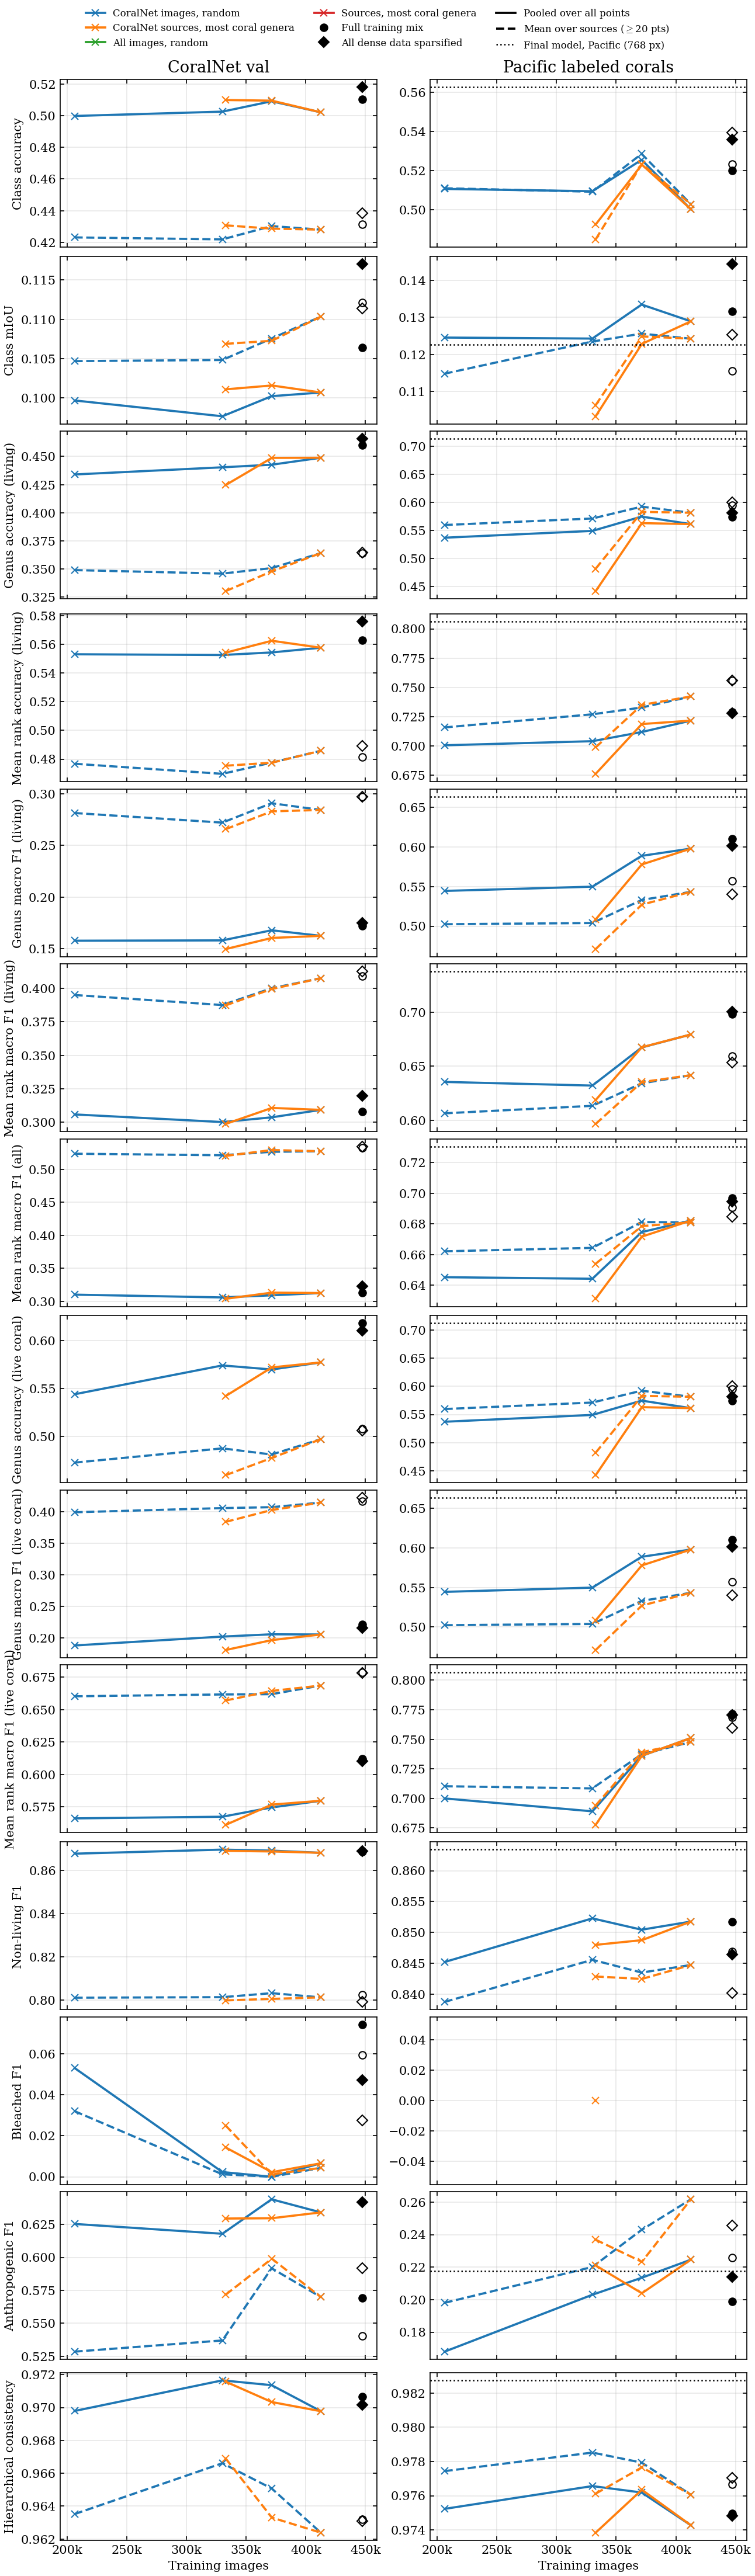

saved reefformer_plots/by_source/data_size.pdf


In [89]:
IMAGE_FORMATTER = mpl.ticker.FuncFormatter(lambda value, _pos: f"{value / 1000:,.0f}k")


def _full_mix_markers(axis, eval_key, key, per_source=False):
    for run, marker, label in ((BASELINE_RUN, "o", BASELINE_LABEL), (SPARSE_RUN, "D", SPARSE_LABEL)):
        if run not in x_full_mix:
            continue
        x = {run: FULL_MIX_IMAGES}
        if per_source:
            colors, _ = SOURCE_COLORS[eval_key]
            sub = source_values(x, eval_key, key).dropna(subset=["_y"])
            axis.scatter(
                np.full(len(sub), FULL_MIX_IMAGES), sub["_y"], s=6, marker=marker,
                c=[colors.get(unit, "gray") for unit in sub["unit"]], alpha=0.6, zorder=2, linewidths=0,
            )
        aggregates = [(pooled(x, eval_key, key), "black")]
        if not per_source:
            aggregates.append((source_mean(x, eval_key, key), "none"))
        for series, face in aggregates:
            y = series.get(run, np.nan)
            if np.isfinite(y):
                axis.plot([FULL_MIX_IMAGES], [y], linestyle="None", marker=marker, markersize=6,
                          color="black", markerfacecolor=face, zorder=5)


def plot_data_size(path, metrics=SCALAR_METRICS):
    fig, ax = plt.subplots(
        len(metrics), len(EVALS), figsize=(8.6, 2.1 * len(metrics)), sharex=True,
        squeeze=False, layout="constrained",
    )
    for col, (eval_key, eval_title) in enumerate(EVALS):
        ax[0, col].set_title(eval_title)
        for row, (key, label) in enumerate(metrics):
            axis = ax[row, col]
            for experiment, _, color in DSIZE_EXPERIMENTS:
                draw_summary(axis, x_size[experiment], eval_key, key, color=color)
            draw_final(axis, eval_key, key)
            _full_mix_markers(axis, eval_key, key)
            axis.grid(True, alpha=0.3)
            axis.xaxis.set_major_formatter(IMAGE_FORMATTER)
            if col == 0:
                axis.set_ylabel(label)
    for axis in ax[-1]:
        axis.set_xlabel("Training images")
    handles = [Line2D([0], [0], color=color, marker="x", label=label) for _, label, color in DSIZE_EXPERIMENTS]
    handles += [
        Line2D([0], [0], color="black", marker="o", linestyle="None", label=BASELINE_LABEL),
        Line2D([0], [0], color="black", marker="D", linestyle="None", label=SPARSE_LABEL),
        *STYLE_HANDLES,
        FINAL_HANDLE,
    ]
    _finish(fig, path, handles=handles, ncol=3)


plot_data_size(f"{PLOTS}/data_size.pdf")

## Data size: one line per source, one figure per experiment

The small dots at 447,411 images are each source's score for the full mix (circles) and the sparsified full
mix (diamonds).

exp1: CoralNet images, random


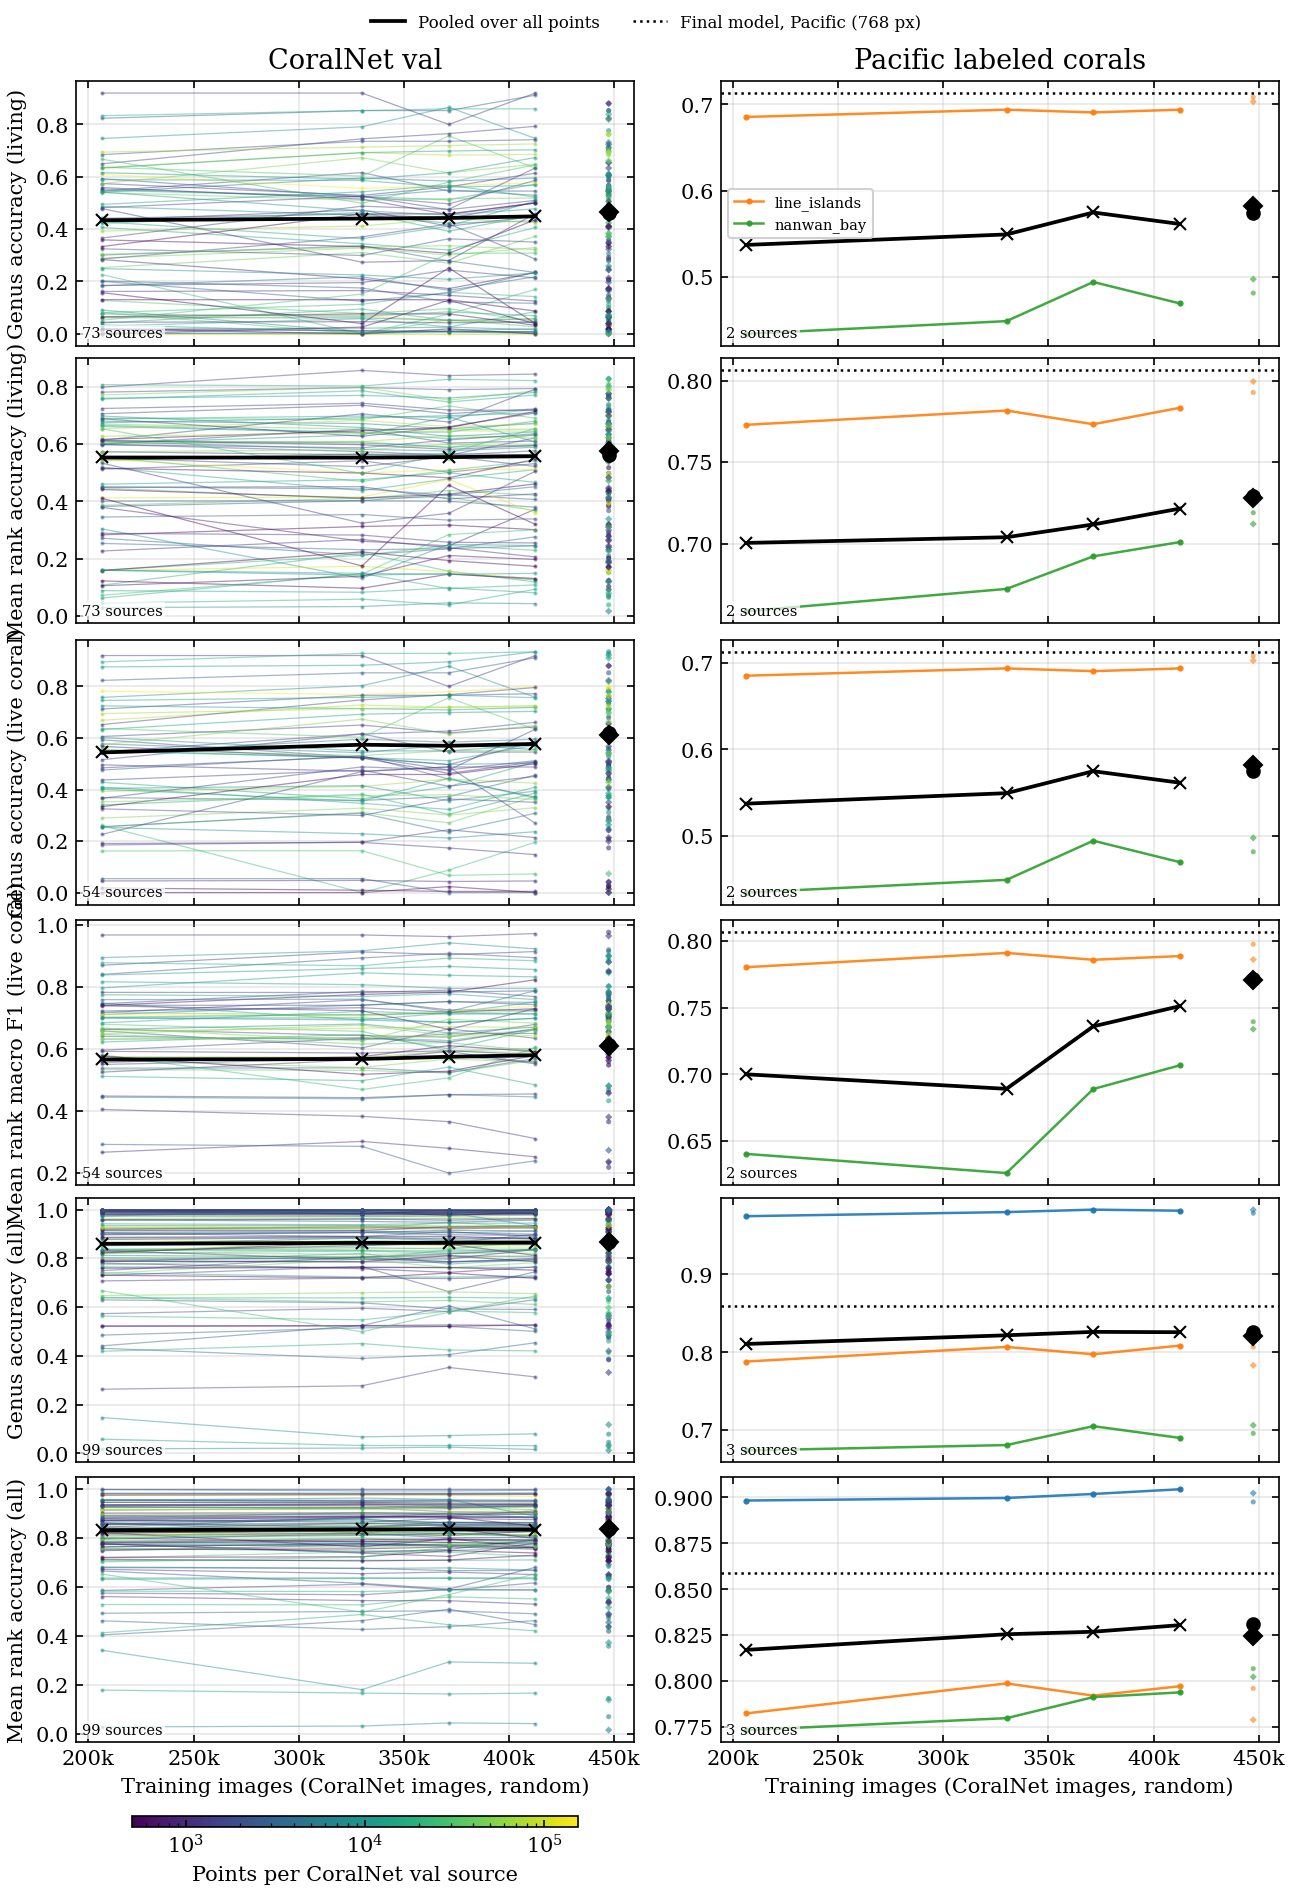

saved reefformer_plots/by_source/data_size_exp1_by_source.pdf
exp2: CoralNet sources, most coral genera


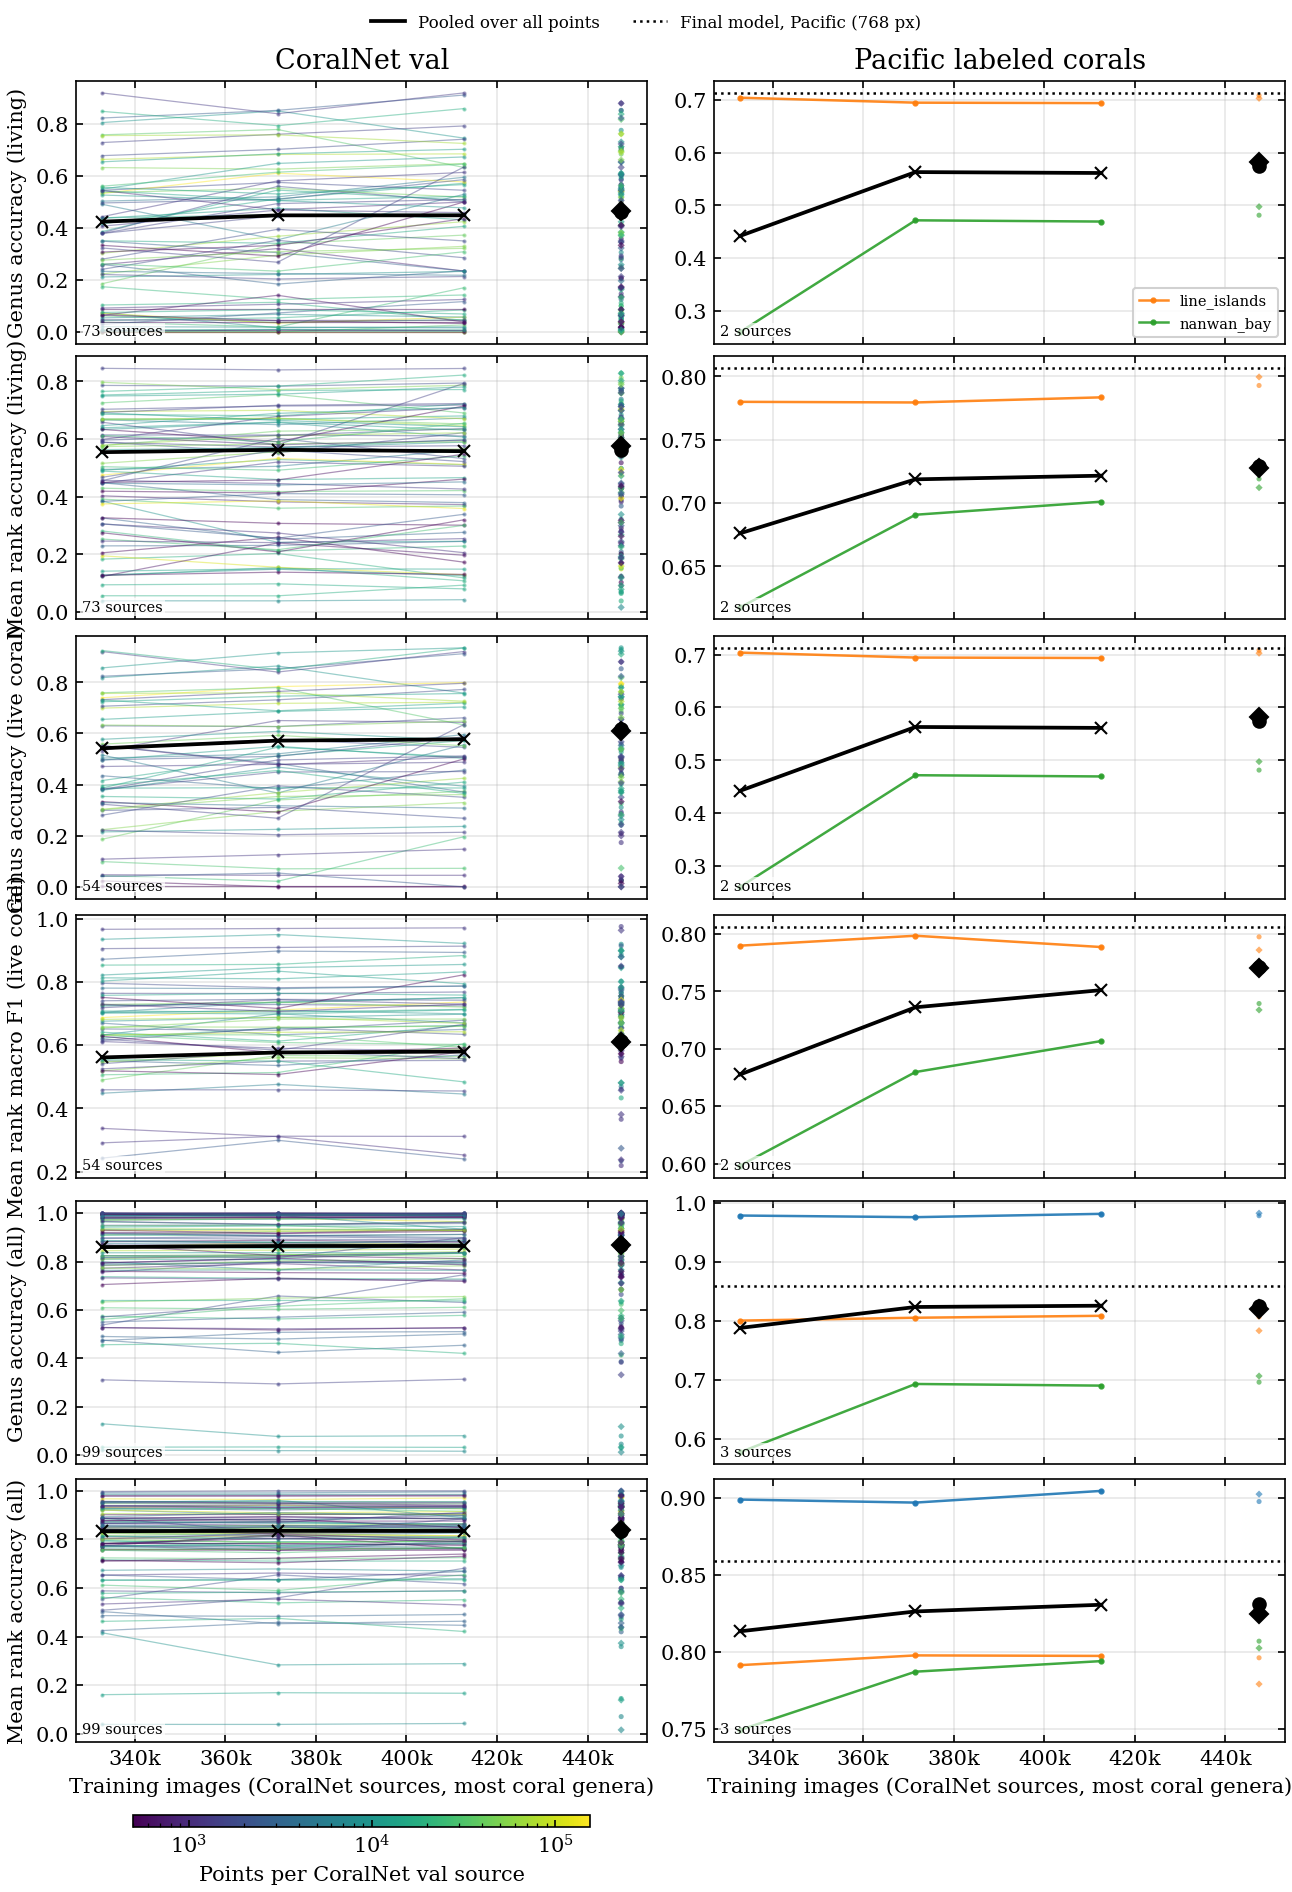

saved reefformer_plots/by_source/data_size_exp2_by_source.pdf
exp3: All images, random
no finished cells for reefformer_plots/by_source/data_size_exp3_by_source.pdf
exp4: Sources, most coral genera
no finished cells for reefformer_plots/by_source/data_size_exp4_by_source.pdf


In [90]:
for experiment, title, _color in DSIZE_EXPERIMENTS:
    print(f"{experiment}: {title}")
    plot_by_source(
        x_size[experiment],
        f"Training images ({title})",
        f"{PLOTS}/data_size_{experiment}_by_source.pdf",
        xformatter=IMAGE_FORMATTER,
        extra=lambda axis, eval_key, key: _full_mix_markers(axis, eval_key, key, per_source=True),
    )

## Data quality: full mix vs. sparsified full mix, per source

Each point is one source, sized by its number of points. Above the diagonal, the sparsified model scores
higher on that source. The star is the pooled score.

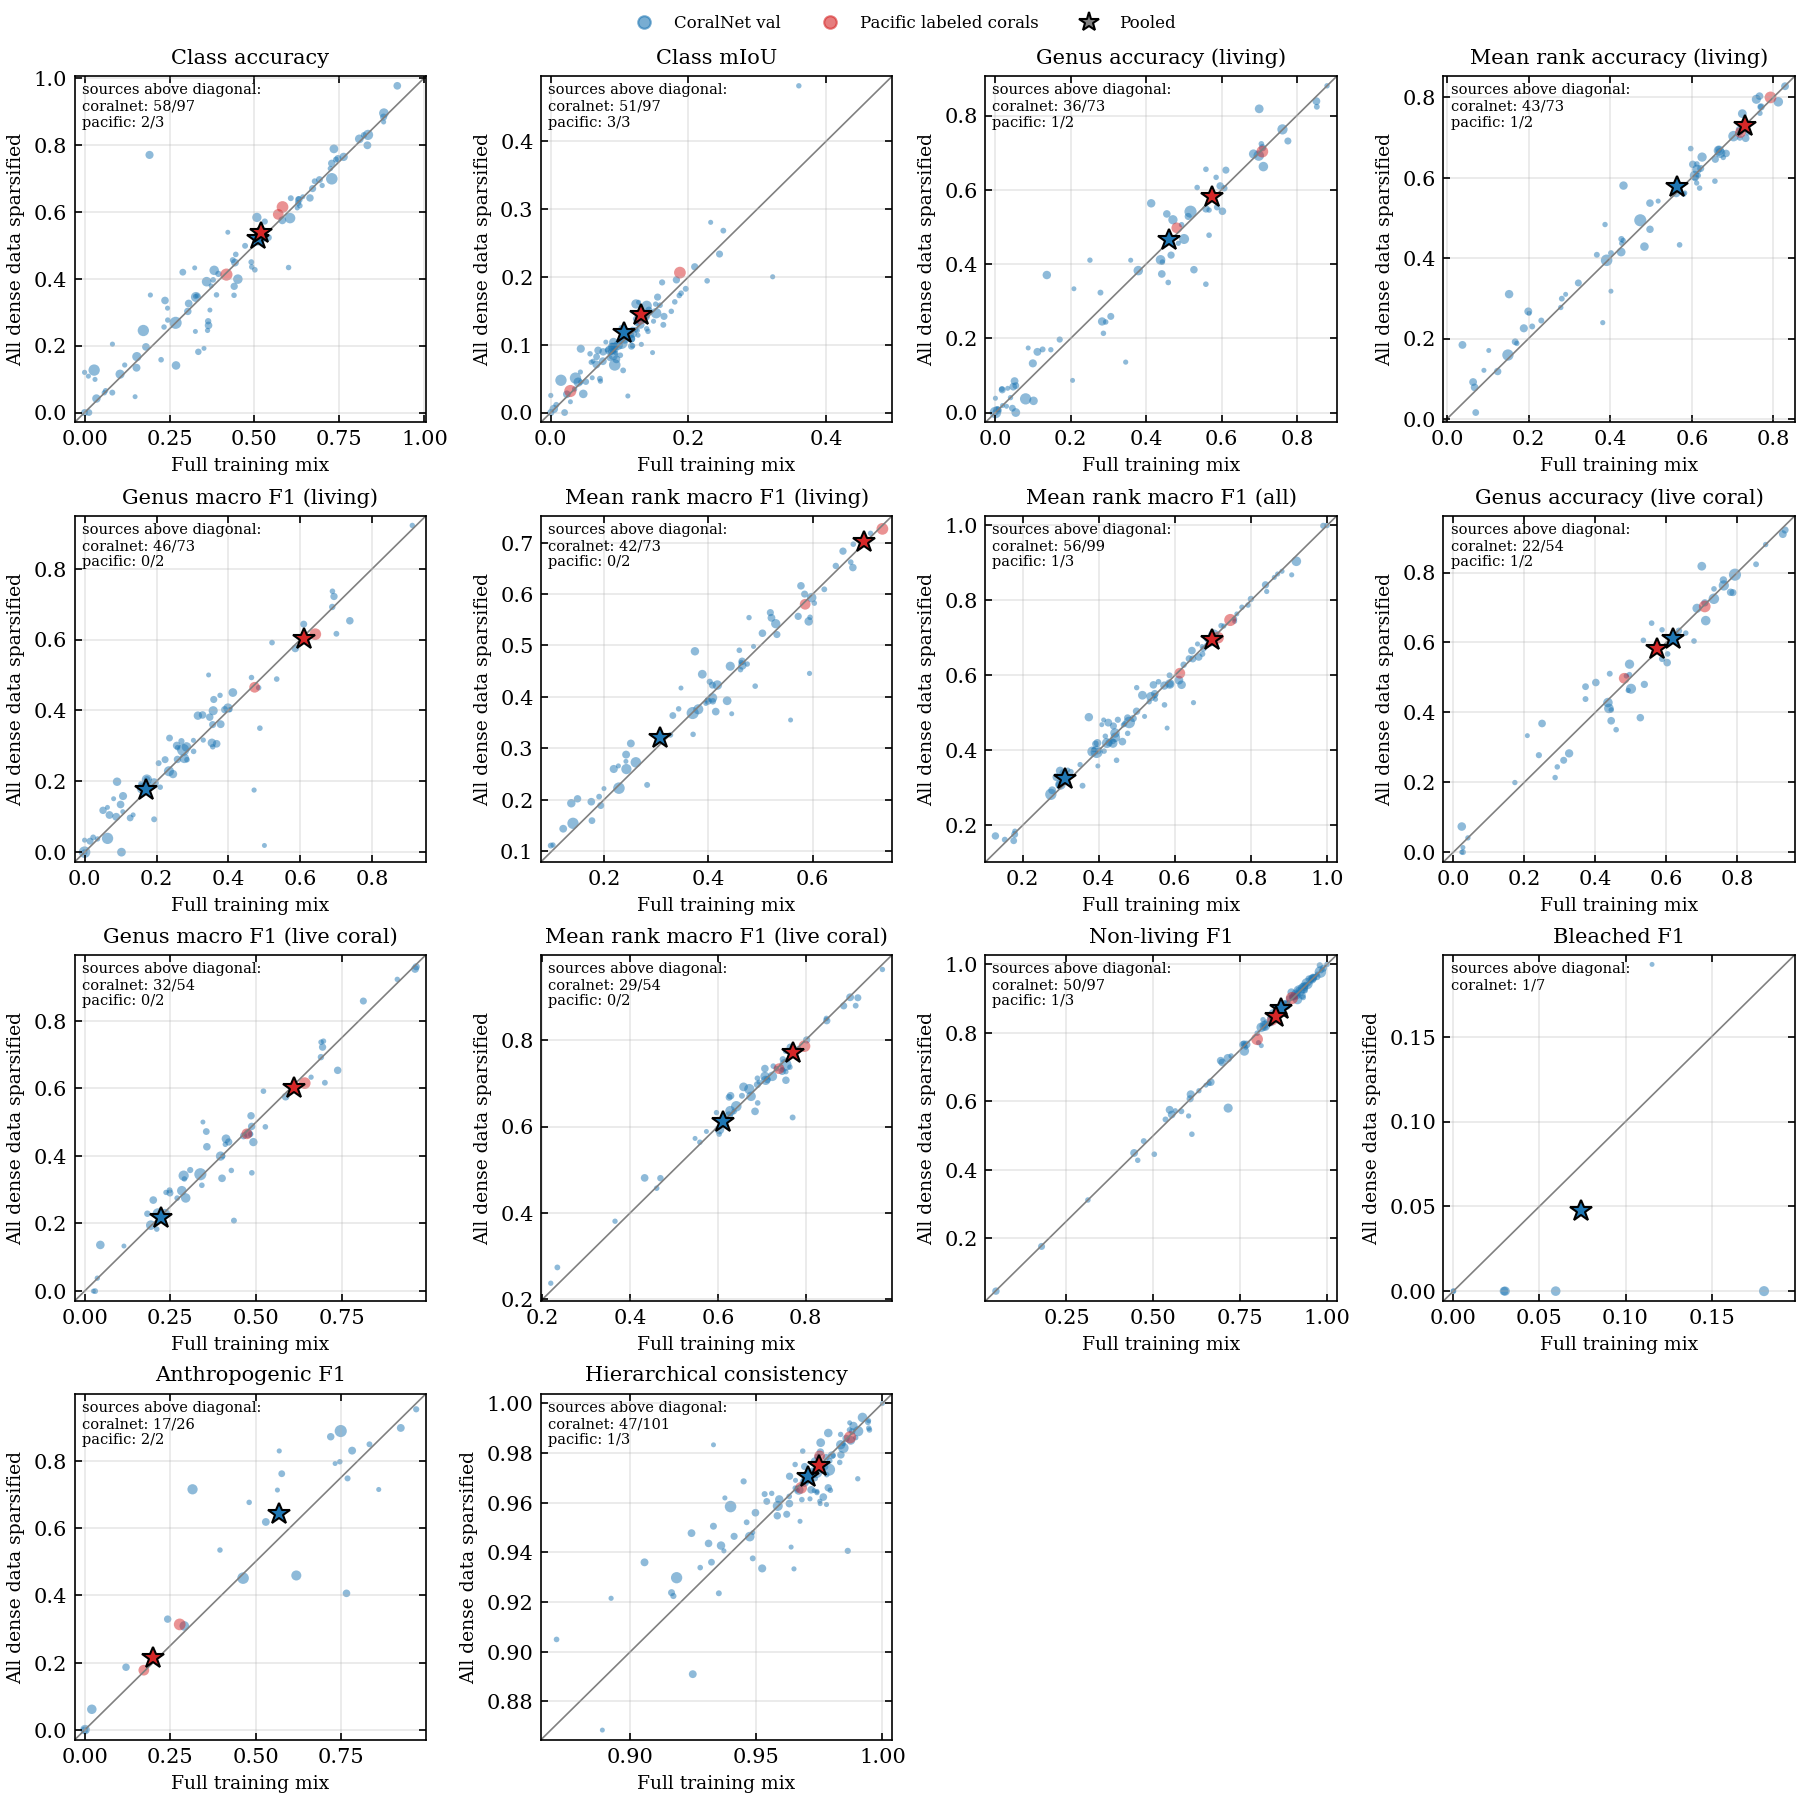

saved reefformer_plots/by_source/data_quality_sparse_by_source.pdf


In [91]:
def plot_paired(run_a, run_b, label_a, label_b, path, metrics=SCALAR_METRICS, ncols=4):
    if run_a not in set(agg["run"]) or run_b not in set(agg["run"]):
        print(f"need both {run_a} and {run_b} in aggregate.csv")
        return
    nrows = int(np.ceil(len(metrics) / ncols))
    fig, ax = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 3.0 * nrows), squeeze=False, layout="constrained")
    eval_colors = {"coralnet": "tab:blue", "pacific": "tab:red"}
    for axis, (key, label) in zip(ax.ravel(), metrics):
        lo, hi = np.inf, -np.inf
        wins = []
        for eval_key, eval_title in EVALS:
            a = source_values({run_a: 0}, eval_key, key).set_index("unit")["_y"]
            b = source_values({run_b: 0}, eval_key, key).set_index("unit")["_y"]
            both = pd.concat([a.rename("a"), b.rename("b")], axis=1).dropna()
            points = per[(per["run"] == run_a) & (per["eval"] == eval_key)].set_index("unit")["num_points"]
            sizes = 4 + 30 * np.sqrt(points.reindex(both.index).fillna(0) / max(points.max(), 1))
            axis.scatter(both["a"], both["b"], s=sizes, color=eval_colors[eval_key], alpha=0.5,
                         linewidths=0, label=eval_title)
            pa = pooled({run_a: 0}, eval_key, key).get(run_a, np.nan)
            pb = pooled({run_b: 0}, eval_key, key).get(run_b, np.nan)
            if np.isfinite(pa) and np.isfinite(pb):
                axis.plot([pa], [pb], marker="*", markersize=11, color=eval_colors[eval_key],
                          markeredgecolor="black", linestyle="None", zorder=5)
            values_ = np.concatenate([both["a"].to_numpy(), both["b"].to_numpy(), [pa, pb]])
            values_ = values_[np.isfinite(values_)]
            if values_.size:
                lo, hi = min(lo, values_.min()), max(hi, values_.max())
            if len(both):
                wins.append(f"{eval_key}: {int((both['b'] > both['a']).sum())}/{len(both)}")
        if np.isfinite(lo):
            pad = 0.03 * max(hi - lo, 1e-3)
            axis.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="gray", linewidth=0.8, zorder=1)
            axis.set_xlim(lo - pad, hi + pad)
            axis.set_ylim(lo - pad, hi + pad)
        axis.set_title(label, fontsize=10)
        if wins:
            axis.text(0.02, 0.98, "sources above diagonal:\n" + "\n".join(wins), transform=axis.transAxes,
                      fontsize=7, va="top")
        axis.grid(True, alpha=0.3)
        axis.set_xlabel(label_a, fontsize=9)
        axis.set_ylabel(label_b, fontsize=9)
    for axis in ax.ravel()[len(metrics):]:
        axis.set_visible(False)
    handles = [
        Line2D([0], [0], color=color, marker="o", linestyle="None", alpha=0.6, label=title)
        for (key, title), color in zip(EVALS, eval_colors.values())
    ]
    handles.append(Line2D([0], [0], color="gray", marker="*", markeredgecolor="black", linestyle="None",
                          markersize=10, label="Pooled"))
    _finish(fig, path, handles=handles, ncol=3)


plot_paired(BASELINE_RUN, SPARSE_RUN, BASELINE_LABEL, SPARSE_LABEL, f"{PLOTS}/data_quality_sparse_by_source.pdf")

## Per-source table for one run

The worst sources on each genus metric (living and live coral, accuracy and macro F1) for one checkpoint,
with their support. This is useful for spotting which sources pull the dashed line down.

In [92]:
from IPython.display import display

WORST_SOURCE_METRICS = [
    "tax_genus_acc_living",
    "tax_genus_macro_f1_living",
    "tax_genus_acc_coral",
    "tax_genus_macro_f1_coral",
]


def worst_sources(run, eval_key="coralnet", key="tax_genus_macro_f1_living", n=15):
    sub = source_values({run: 0}, eval_key, key)
    cols = ["unit", "num_points", _support_column(key), "_y"]
    return sub[cols].rename(columns={"_y": key}).dropna(subset=[key]).sort_values(key).head(n)


for key in WORST_SOURCE_METRICS:
    print(f"{BASELINE_RUN}: {label_of(key)}")
    display(worst_sources(BASELINE_RUN, key=key))

cbm_vitsize_vitl: Genus accuracy (living)


,unit,num_points,tax_genus_n_living,tax_genus_acc_living
4,450,123996,150,0.000000
85,6522,640,78,0.000000
10,1368,3008,217,0.000000
88,6620,13068,6232,0.004332
23,2922,18225,2157,0.006490
80,6207,2500,411,0.017032
26,3156,9200,2101,0.018087
70,5582,520,53,0.018868
77,5981,520,237,0.029536
76,5980,520,92,0.032609


cbm_vitsize_vitl: Genus macro F1 (living)


,unit,num_points,tax_genus_n_living,tax_genus_macro_f1_living
85,6522,640,78,0.000000
10,1368,3008,217,0.000000
4,450,123996,150,0.000000
26,3156,9200,2101,0.015147
80,6207,2500,411,0.023946
79,6068,1100,474,0.036153
88,6620,13068,6232,0.051290
76,5980,520,92,0.063590
5,466,112104,7199,0.063880
15,1749,17460,1417,0.069231


cbm_vitsize_vitl: Genus accuracy (live coral)


,unit,num_points,tax_genus_n_coral,tax_genus_acc_coral
76,5980,520,43,0.023256
21,2808,29000,1064,0.023496
77,5981,520,224,0.026786
80,6207,2500,74,0.027027
79,6068,1100,466,0.040773
86,6573,1200,231,0.173160
65,5339,500,24,0.208333
8,683,4070,328,0.240854
96,7121,16000,1141,0.249781
73,5760,1500,628,0.286624


cbm_vitsize_vitl: Genus macro F1 (live coral)


,unit,num_points,tax_genus_n_coral,tax_genus_macro_f1_coral
76,5980,520,43,0.025641
80,6207,2500,74,0.030769
79,6068,1100,466,0.037105
21,2808,29000,1064,0.045914
77,5981,520,224,0.114697
25,2971,5600,875,0.182997
39,3692,51775,11037,0.192909
96,7121,16000,1141,0.200140
73,5760,1500,628,0.210368
48,4430,79651,25341,0.213586


## Validation sources: rank accuracy and example images

One page per CoralNet validation source. The top row is that source's accuracy and macro F1
at each rank across the loss-weight sweep (one line per rank), on living points and on live
coral points. A rank is drawn only where the source has at least `MIN_SUPPORT` points in that
scope. The bottom row is five images from the source with the annotation points used in the
re-evaluation drawn on top: the validation image blacklist and annotation overrides from
`configs/data_config_dedup.yaml`.

In [93]:
import json
import sys
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import pyarrow.dataset as ds
from matplotlib.backends.backend_pdf import PdfPages

_SCRIPTS = Path("scripts").resolve()
if str(_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(_SCRIPTS))

from make_appendix_figures import (  # noqa: E402
    CORALNET_LEGEND_FONTSIZE,
    CORALNET_LEGEND_WRAP,
    assign_colors,
    draw_points,
    point_handle,
    title_label,
)
from make_coralnet_source_examples import (  # noqa: E402
    BUCKET,
    POINT_SCALE,
    fetch_resized,
    sample_order,
)

N_EXAMPLE_IMAGES = 5
SPARE_IMAGES = 2
EXAMPLE_MAX_EDGE = 640
EXAMPLE_WORKERS = 12
MANIFEST = Path(".cache/coralnet_source_examples/manifest.parquet")
ID2NAME_PATH = Path(".cache/coralnet_source_examples/coralnet_id2name.json")
IMAGE_CACHE = Path(".cache/coralnet_source_examples/images")
BLACKLIST_PATH = Path("configs/coralnet/image_blacklist.parquet")
OVERRIDES_PATH = Path("configs/coralnet/annotation_overrides.parquet")


def _rgb01(color):
    return tuple(float(channel) / 255.0 for channel in color)


def _label_names(coralnet_ids, id2name):
    names = coralnet_ids.map(lambda cid: id2name.get(str(int(cid))))
    return names.fillna(coralnet_ids.astype(str)).astype(str).str.lower()


def _legend_handles(labels, colors):
    return [
        point_handle(title_label(name, CORALNET_LEGEND_WRAP), _rgb01(colors[name]))
        for name in sorted(set(labels), key=str.casefold)
        if name in colors
    ]


def _legend_extent(handles, ncol):
    """Legend ``(width, height)`` in inches at ``ncol`` columns."""
    fig = plt.figure(figsize=(2.0, 2.0))
    legend = fig.legend(
        handles=list(handles),
        ncol=ncol,
        loc="center",
        frameon=False,
        handlelength=1.0,
        handleheight=1.0,
        handletextpad=0.45,
        columnspacing=1.3,
        labelspacing=0.28,
        borderaxespad=0.0,
        borderpad=0.0,
        fontsize=CORALNET_LEGEND_FONTSIZE,
    )
    bbox = legend.get_window_extent(fig.canvas.get_renderer())
    plt.close(fig)
    return bbox.width / fig.dpi, bbox.height / fig.dpi


def _draw_overlay(image, points, colors, scale):
    scaled = points.copy()
    scaled["row"] = scaled["row"].astype(float) * scale
    scaled["col"] = scaled["col"].astype(float) * scale
    return draw_points(image, scaled, colors, point_scale=POINT_SCALE)


def load_val_examples(source_ids, n_images=N_EXAMPLE_IMAGES, seed=0):
    """Five overlaid images per source, using the validation blacklist and overrides.

    Returns ``source_id -> (images, labels, colors)``. Images are already drawn.
    """
    if not MANIFEST.is_file():
        raise FileNotFoundError(f"missing {MANIFEST}; run scripts/make_coralnet_source_examples.py once")
    id2name = {str(key): str(value) for key, value in json.loads(ID2NAME_PATH.read_text()).items()}
    blacklist = set(pd.read_parquet(BLACKLIST_PATH)["image_id"].astype(str))
    overrides = pd.read_parquet(OVERRIDES_PATH, columns=["image_id", "row", "col", "coralnet_id"])
    overrides["image_id"] = overrides["image_id"].astype(str)

    dataset = ds.dataset(str(MANIFEST), format="parquet")
    index = dataset.to_table(
        columns=["source_id", "image_id", "image_s3_key"],
        filter=ds.field("source_id").isin([int(source) for source in source_ids]),
    ).to_pandas()
    index["source_id"] = index["source_id"].astype(int)
    index["image_id"] = index["image_id"].astype(str)
    index = index[index["image_s3_key"].map(lambda key: isinstance(key, str) and bool(key))]
    index = index.drop_duplicates(["source_id", "image_id"])
    index = index[~index["image_id"].isin(blacklist)]

    queues = {}
    for source_id, group in index.groupby("source_id"):
        keys = dict(zip(group["image_id"], group["image_s3_key"], strict=True))
        ordered = sample_order(list(keys), seed, int(source_id))
        take = min(len(ordered), n_images + SPARE_IMAGES)
        queues[int(source_id)] = [(image_id, str(keys[image_id])) for image_id in ordered[:take]]

    queued = pd.DataFrame(
        [(sid, image_id) for sid, queue in queues.items() for image_id, _key in queue],
        columns=["source_id", "image_id"],
    )
    points = dataset.to_table(
        columns=["source_id", "image_id", "row", "col", "coralnet_id"],
        filter=ds.field("image_id").isin(queued["image_id"].tolist()),
    ).to_pandas()
    points["source_id"] = points["source_id"].astype(int)
    points["image_id"] = points["image_id"].astype(str)
    points = points.merge(queued, on=["source_id", "image_id"])
    replaced = set(overrides["image_id"]) & set(queued["image_id"])
    if replaced:
        repl = overrides[overrides["image_id"].isin(replaced)].merge(queued, on="image_id")
        points = points[~points["image_id"].isin(replaced)]
        points = pd.concat([points, repl], ignore_index=True)
    points["source_label_name"] = _label_names(points["coralnet_id"], id2name)
    by_image = {
        (int(sid), str(image_id)): frame
        for (sid, image_id), frame in points.groupby(["source_id", "image_id"], sort=False)
    }

    tasks = [
        (source_id, image_id, key)
        for source_id, queue in queues.items()
        for image_id, key in queue
        if (source_id, image_id) in by_image
    ]

    def _fetch(task):
        source_id, image_id, key = task
        image, scale = fetch_resized(BUCKET, key, IMAGE_CACHE / key, EXAMPLE_MAX_EDGE)
        return source_id, image_id, image, scale

    fetched = {}
    done = 0
    with ThreadPoolExecutor(max_workers=EXAMPLE_WORKERS) as pool:
        futures = {pool.submit(_fetch, task): task for task in tasks}
        for future in as_completed(futures):
            task = futures[future]
            try:
                source_id, image_id, image, scale = future.result()
            except Exception as exc:  # noqa: BLE001
                print(f"source {task[0]} image {task[1]} failed: {exc}")
                continue
            fetched[(source_id, image_id)] = (image, scale)
            done += 1
            if done % 50 == 0 or done == len(tasks):
                print(f"fetched {done}/{len(tasks)} images")

    examples = {}
    for source_id, queue in queues.items():
        picked = []
        for image_id, _key in queue:
            hit = fetched.get((source_id, image_id))
            frame = by_image.get((source_id, image_id))
            if hit is None or frame is None or frame.empty:
                continue
            picked.append((hit[0], frame, hit[1]))
            if len(picked) == n_images:
                break
        if not picked:
            examples[source_id] = ([], [], {})
            continue
        shown = pd.concat([frame for _image, frame, _scale in picked], ignore_index=True)
        order = shown["source_label_name"].value_counts()
        colors = assign_colors(order.index.astype(str).tolist())
        images = []
        labels = []
        for image, frame, scale in picked:
            labels.extend(frame["source_label_name"].astype(str).tolist())
            images.append(_draw_overlay(image, frame, colors, scale))
        examples[source_id] = (images, labels, colors)
    return examples


# Panels of a source page: (rank metric, panel title, points it is scored on).
CARD_METRICS = [
    ("acc_living", "Accuracy (living)", "living"),
    ("macro_f1_living", "Macro F1 (living)", "living"),
    ("acc_coral", "Accuracy (live coral)", "live coral"),
    ("macro_f1_coral", "Macro F1 (live coral)", "live coral"),
]


def _rank_frame(x):
    frames = []
    for metric, _title, _scope in CARD_METRICS:
        for rank in RANKS:
            sub = source_values(x, "coralnet", f"tax_{rank}_{metric}")
            frames.append(sub.assign(metric=metric, rank=rank)[["unit", "run", "metric", "rank", "_y"]])
    return pd.concat(frames, ignore_index=True)


def _draw_rank_panel(axis, rows, x, title, scope, xlabel, xlim=None):
    for rank in RANKS:
        series = rows.loc[rows["rank"] == rank].drop_duplicates("run").set_index("run")["_y"]
        _line(axis, series, x, color=RANK_COLORS[rank], marker="o", markersize=3.5, label=rank)
    if xlim:
        axis.set_xlim(*xlim)
    axis.set_ylim(0, 1)
    axis.set_xlabel(xlabel, fontsize=8)
    axis.set_title(title, fontsize=10)
    axis.tick_params(labelsize=8)
    axis.grid(True, alpha=0.3)
    if not axis.get_legend_handles_labels()[0]:
        axis.text(
            0.5, 0.5, f"fewer than {MIN_SUPPORT} {scope} points",
            transform=axis.transAxes, ha="center", va="center", fontsize=8, color="0.35",
        )


def _compose_source_card(source_id, x, xlabel, rank_rows, example, n_points, xlim=None):
    """Top: each CARD_METRICS metric at every rank. Bottom: annotated images and their legend."""
    images, labels, colors = example if example else ([], [], {})
    handles = _legend_handles(labels, colors)
    ncol = 1 if len(handles) <= 16 else 2
    legend_w, legend_h = (0.2, 0.2)
    if handles:
        legend_w, legend_h = _legend_extent(handles, ncol)
        legend_w += 0.14

    fig_w = 13.0
    margin = 0.10
    legend_gap = 0.12
    strip_x = margin
    legend_x = fig_w - margin - legend_w
    strip_w = legend_x - legend_gap - strip_x
    if strip_w < 8.0:
        fig_w += 8.0 - strip_w
        legend_x = fig_w - margin - legend_w
        strip_w = legend_x - legend_gap - strip_x
    image_gap = 0.035
    cell_w = (strip_w - image_gap * (N_EXAMPLE_IMAGES - 1)) / N_EXAMPLE_IMAGES
    cell_h = max(1.25, 0.78 * cell_w)
    content_h = max(cell_h, legend_h)
    bottom = 0.10
    row_gap = 0.62
    plot_h = 2.1
    top = 0.62
    fig_h = bottom + content_h + row_gap + plot_h + top

    fig = plt.figure(figsize=(fig_w, fig_h))
    fig.patch.set_facecolor("white")
    fig.suptitle(
        f"Source {source_id}  ({n_points:,} points)", x=margin / fig_w, y=1 - 0.08 / fig_h, ha="left", va="top",
    )
    tick_space = 0.32
    panel_gap = 0.18
    n_panels = len(CARD_METRICS)
    panel_w = (fig_w - 2 * margin - n_panels * tick_space - (n_panels - 1) * panel_gap) / n_panels
    plot_bottom = bottom + content_h + row_gap
    for index, (metric, title, scope) in enumerate(CARD_METRICS):
        left = margin + tick_space + index * (panel_w + tick_space + panel_gap)
        axis = fig.add_axes([left / fig_w, plot_bottom / fig_h, panel_w / fig_w, plot_h / fig_h])
        _draw_rank_panel(axis, rank_rows[rank_rows["metric"] == metric], x, title, scope, xlabel, xlim=xlim)
    fig.legend(
        handles=[Line2D([0], [0], color=RANK_COLORS[rank], marker="o", markersize=3.5, label=rank) for rank in RANKS],
        ncol=len(RANKS),
        loc="upper right",
        bbox_to_anchor=(1 - margin / fig_w, 1 - 0.06 / fig_h),
        frameon=False,
        fontsize=8,
    )

    row_bottom = bottom + max(0.0, (content_h - cell_h) / 2)
    if not images:
        empty = fig.add_axes([strip_x / fig_w, row_bottom / fig_h, strip_w / fig_w, cell_h / fig_h])
        empty.set_axis_off()
        empty.text(0.5, 0.5, "no images", ha="center", va="center", fontsize=9)
    for index, image in enumerate(images):
        aspect = image.size[0] / image.size[1]
        if aspect >= cell_w / cell_h:
            disp_w, disp_h = cell_w, cell_w / aspect
        else:
            disp_h, disp_w = cell_h, cell_h * aspect
        x_in = strip_x + index * (cell_w + image_gap) + (cell_w - disp_w) / 2
        y_in = row_bottom + (cell_h - disp_h) / 2
        axes = fig.add_axes([x_in / fig_w, y_in / fig_h, disp_w / fig_w, disp_h / fig_h])
        axes.imshow(np.asarray(image), interpolation="none")
        axes.set_axis_off()
    if handles:
        fig.legend(
            handles=handles,
            ncol=ncol,
            loc="center",
            frameon=False,
            handlelength=1.0,
            handleheight=1.0,
            handletextpad=0.45,
            columnspacing=1.3,
            labelspacing=0.28,
            borderaxespad=0.0,
            borderpad=0.0,
            fontsize=CORALNET_LEGEND_FONTSIZE,
            bbox_to_anchor=((legend_x + legend_w / 2) / fig_w, (row_bottom + cell_h / 2) / fig_h),
        )
    return fig


def plot_val_source_cards(x, xlabel, path, source_ids=None, xlim=None):
    """Multipage PDF, one validation source per page."""
    if not x:
        print(f"no finished cells for {path}")
        return
    if source_ids is None:
        source_ids = sorted(int(unit) for unit in per.loc[per["eval"] == "coralnet", "unit"].unique())
    print(f"{len(source_ids)} validation sources")
    examples = load_val_examples(source_ids)
    rank_rows = _rank_frame(x)
    rank_rows["unit"] = rank_rows["unit"].astype(str)
    point_counts = (
        per.loc[per["eval"] == "coralnet", ["unit", "num_points"]]
        .drop_duplicates("unit")
        .assign(unit=lambda frame: frame["unit"].astype(str))
        .set_index("unit")["num_points"]
    )
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    failed = []
    with PdfPages(path) as pdf:
        for source_id in source_ids:
            try:
                fig = _compose_source_card(
                    source_id,
                    x,
                    xlabel,
                    rank_rows[rank_rows["unit"] == str(source_id)],
                    examples.get(int(source_id), ([], [], {})),
                    int(point_counts.get(str(source_id), 0)),
                    xlim=xlim,
                )
            except Exception as exc:  # noqa: BLE001
                failed.append(source_id)
                print(f"source {source_id} failed: {exc}")
                plt.close("all")
                continue
            pdf.savefig(fig)
            plt.close(fig)
    print(f"saved {path} ({len(source_ids) - len(failed)} pages)")
    if failed:
        print(f"failed sources: {failed}")


plot_val_source_cards(
    x_loss,
    LOSS_WEIGHT_LABEL,
    f"{PLOTS}/coralnet_val_rank_accuracy.pdf",
    xlim=(0, 1),
)

101 validation sources
fetched 50/707 images
fetched 100/707 images
fetched 150/707 images
fetched 200/707 images
fetched 250/707 images
fetched 300/707 images
fetched 350/707 images
fetched 400/707 images
fetched 450/707 images
fetched 500/707 images
fetched 550/707 images
fetched 600/707 images
fetched 650/707 images
fetched 700/707 images
fetched 707/707 images
saved reefformer_plots/by_source/coralnet_val_rank_accuracy.pdf (101 pages)
